<a href="https://colab.research.google.com/github/shreyasshikhare11/FastNet-machine-learning-weather-prediction-models-through-loss-function-design/blob/main/FastNet_Improving_the_physical_consistency_of_machine_learning_weather_prediction_models_through_loss_function_design.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch_harmonics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 750.8/750.8 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 76.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.5/

In [ ]:
!pip install earthkit

# FastNet: AI for Physical-Consistent Weather Prediction
https://arxiv.org/pdf/2509.17601

FastNet mesh grid

In [ ]:
"""
fastnet/mesh.py
==============================================
"""

import numpy as np
import torch
from typing import Dict, List, Tuple

# ── Constants ──────────────────────────────────────────────────────────────
_PHI = (1.0 + np.sqrt(5.0)) / 2.0          # golden ratio

N_EDGE_FEATURES = 7   # [Δx, Δy, Δz, dist_norm, ux, uy, uz]

_ICOSA_VERTICES_RAW = np.array([
    [-1,  _PHI, 0], [ 1,  _PHI, 0], [-1, -_PHI, 0], [ 1, -_PHI, 0],
    [0, -1,  _PHI], [0,  1,  _PHI], [0, -1, -_PHI], [0,  1, -_PHI],
    [ _PHI, 0, -1], [ _PHI, 0,  1], [-_PHI, 0, -1], [-_PHI, 0,  1],
], dtype=np.float64)

_ICOSA_EDGES = [
    (0,1),(0,5),(0,7),(0,10),(0,11),(1,5),(1,7),(1,8),(1,9),
    (2,3),(2,4),(2,6),(2,10),(2,11),(3,4),(3,6),(3,8),(3,9),
    (4,5),(4,9),(4,11),(5,9),(5,11),(6,7),(6,8),(6,10),
    (7,8),(7,10),(8,9),(10,11),
]

_ICOSA_FACES = [
    (0,1,5),(0,1,7),(0,5,11),(0,7,10),(0,10,11),
    (1,5,9),(1,7,8),(1,8,9),
    (2,3,4),(2,3,6),(2,4,11),(2,6,10),(2,10,11),(3,6,8),(3,8,9),(3,4,9),
    (4,5,9),(4,5,11),(6,7,8),(6,7,10),
]


# ── Geometry helpers ───────────────────────────────────────────────────────

def _normalise(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v, axis=-1, keepdims=True)
    return v / n

def _xyz_to_latlon(xyz: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    lat = np.degrees(np.arcsin(np.clip(xyz[:, 2], -1, 1)))
    lon = np.degrees(np.arctan2(xyz[:, 1], xyz[:, 0]))
    return lat, lon

def latlon_to_xyz(latlon_deg: np.ndarray) -> np.ndarray:
    """Convert (lat, lon) in degrees to unit-sphere (x, y, z)."""
    lat = np.radians(latlon_deg[:, 0])
    lon = np.radians(latlon_deg[:, 1])
    x = np.cos(lat) * np.cos(lon)
    y = np.cos(lat) * np.sin(lon)
    z = np.sin(lat)
    return np.stack([x, y, z], axis=-1)

def _haversine_batch(query: np.ndarray, keys: np.ndarray) -> np.ndarray:
    """Haversine distances: (B,2) vs (K,2) → (B,K) radians."""
    q = np.radians(query)
    k = np.radians(keys)
    dlat = k[:, 0] - q[:, 0:1]
    dlon = k[:, 1] - q[:, 1:2]
    a = np.sin(dlat/2)**2 + np.cos(q[:, 0:1]) * np.cos(k[:, 0]) * np.sin(dlon/2)**2
    return 2.0 * np.arcsin(np.clip(np.sqrt(a), 0, 1))


# ── Edge feature construction (FIX-3) ─────────────────────────────────────

def build_edge_features_np(
    src_xyz: np.ndarray,   # (E, 3) unit-sphere Cartesian
    dst_xyz: np.ndarray,   # (E, 3)
) -> np.ndarray:
    """
    7-dim edge attributes from node positions (paper Section 2b):
      [0:3]  Δ = dst_xyz − src_xyz               (relative position vector)
      [3]    |Δ| / (2π)                           (normalised great-circle distance)
      [4:7]  Δ / |Δ|                              (unit direction vector)

    These encode the length and orientation of each edge on the sphere
    so the GNN can learn distance-dependent and direction-dependent messages.
    """
    diff  = dst_xyz - src_xyz                              # (E, 3)
    dist  = np.linalg.norm(diff, axis=-1, keepdims=True) + 1e-8
    unit  = diff / dist
    dist_norm = dist / (2.0 * np.pi)
    return np.concatenate([diff, dist_norm, unit], axis=-1).astype(np.float32)


# ── Icosahedral mesh ───────────────────────────────────────────────────────

class IcosahedralMesh:
    """
    Multi-scale icosahedral mesh for global weather modelling.

    Parameters
    ----------
    refinement_level : int
        N=5 → ~10 242 nodes (~2° spacing, O96).
        N=6 → ~40 962 nodes (~1° spacing, N320).
    """

    def __init__(self, refinement_level: int = 5):
        self.N = refinement_level
        self.nodes_xyz, self.edges = self._build()           # FIX-1, FIX-2
        self.nodes_latlon = np.stack(_xyz_to_latlon(self.nodes_xyz), axis=-1)
        self.all_edges    = np.concatenate(self.edges, axis=0)

    # ── FIX-1 + FIX-2: corrected subdivision ──────────────────────────────

    def _build(self) -> Tuple[np.ndarray, List[np.ndarray]]:
        """
        Build icosahedral mesh using a Python list for vertices (FIX-1)
        and a running set of already-seen edges to isolate new edges at
        each refinement level (FIX-2).
        """
        # Use a Python list so .append() works cleanly
        vertices: List[np.ndarray] = [
            _normalise(v[np.newaxis])[0] for v in _ICOSA_VERTICES_RAW
        ]

        edges_per_level: List[np.ndarray] = []
        cumulative_edges: set = set()

        # Level-0: base icosahedron edges
        base_set = {(min(a, b), max(a, b)) for a, b in _ICOSA_EDGES}
        cumulative_edges.update(base_set)
        edges_per_level.append(np.array(sorted(base_set), dtype=np.int64))

        faces = list(_ICOSA_FACES)
        midpoint_cache: Dict[Tuple[int, int], int] = {}

        for _level in range(1, self.N + 1):
            new_faces: List[Tuple] = []
            candidate_edges: set = set()

            for face in faces:
                v0, v1, v2 = face

                m01 = self._midpoint_idx(vertices, v0, v1, midpoint_cache)
                m12 = self._midpoint_idx(vertices, v1, v2, midpoint_cache)
                m02 = self._midpoint_idx(vertices, v0, v2, midpoint_cache)

                new_faces += [
                    (v0,  m01, m02),
                    (v1,  m12, m01),
                    (v2,  m02, m12),
                    (m01, m12, m02),
                ]
                for a, b in [
                    (v0, m01), (v0, m02), (v1, m01), (v1, m12),
                    (v2, m02), (v2, m12), (m01, m12), (m01, m02), (m12, m02)
                ]:
                    candidate_edges.add((min(a, b), max(a, b)))

            faces = new_faces

            # FIX-2: keep only edges that did NOT exist at coarser levels
            new_only = candidate_edges - cumulative_edges
            cumulative_edges.update(new_only)
            if new_only:
                edges_per_level.append(
                    np.array(sorted(new_only), dtype=np.int64)
                )

        vertices_arr = np.array(vertices, dtype=np.float64)
        return vertices_arr, edges_per_level

    @staticmethod
    def _midpoint_idx(
        vertices: List[np.ndarray],
        v0: int, v1: int,
        cache: Dict[Tuple[int, int], int],
    ) -> int:
        """Return index of midpoint vertex, creating it if needed."""
        key = (min(v0, v1), max(v0, v1))
        if key not in cache:
            mp = _normalise((vertices[v0] + vertices[v1])[np.newaxis] / 2.0)[0]
            cache[key] = len(vertices)
            vertices.append(mp)
        return cache[key]

    # ── KNN connectivity ──────────────────────────────────────────────────

    def knn_grid_to_mesh(
        self, grid_latlon: np.ndarray, k: int = 4
    ) -> Tuple[np.ndarray, np.ndarray]:
        """KNN from grid points → mesh nodes. Returns (src_grid, dst_mesh)."""
        G = grid_latlon.shape[0]
        M = self.nodes_latlon.shape[0]
        src_list, dst_list = [], []
        batch = 512
        for i in range(0, G, batch):
            g_batch = grid_latlon[i:i+batch]
            d = _haversine_batch(g_batch, self.nodes_latlon)   # (B, M)
            knn = np.argpartition(d, k, axis=-1)[:, :k]
            B = g_batch.shape[0]
            src_list.append(np.repeat(np.arange(i, i+B), k))
            dst_list.append(knn.ravel())
        return np.concatenate(src_list), np.concatenate(dst_list)

    def knn_mesh_to_grid(
        self, grid_latlon: np.ndarray, k: int = 3
    ) -> Tuple[np.ndarray, np.ndarray]:
        """KNN from mesh nodes → grid points. Returns (src_mesh, dst_grid)."""
        G = grid_latlon.shape[0]
        src_all, dst_all = [], []
        batch = 512
        for i in range(0, G, batch):
            g_batch = grid_latlon[i:i+batch]
            d = _haversine_batch(g_batch, self.nodes_latlon)   # (B, M)
            knn = np.argpartition(d, k, axis=-1)[:, :k]       # (B, k)
            B = g_batch.shape[0]
            # src = mesh indices, dst = grid indices
            src_all.append(knn.ravel())
            dst_all.append(np.repeat(np.arange(i, i+B), k))
        return np.concatenate(src_all), np.concatenate(dst_all)

    # ── FIX-3: complete graph construction ────────────────────────────────

    def build_complete_graph(
        self,
        grid_latlon: np.ndarray,    # (G, 2) latitude/longitude in degrees
        k_grid_to_mesh: int = 4,
        k_mesh_to_grid: int = 3,
    ) -> Dict[str, torch.Tensor]:
        """
        Build the full graph dict that FastNet's forward() expects.

        All three edge sets receive genuine 7-dim geometric edge features
        (previously demo code used random tensors).

        Returns
        -------
        dict with keys:
          grid_to_mesh_edges       (2, E1)   [src_grid, dst_mesh]
          grid_to_mesh_edge_attr   (E1, 7)
          mesh_edges               (2, E2)   bidirectional, all levels
          mesh_edge_attr           (E2, 7)
          mesh_to_grid_edges       (2, E3)   [src_mesh, dst_grid], sorted by dst
        """
        grid_xyz = latlon_to_xyz(grid_latlon)    # (G, 3)
        mesh_xyz = self.nodes_xyz                # (M, 3)

        # ── Grid → Mesh ────────────────────────────────────────────────
        g2m_src, g2m_dst = self.knn_grid_to_mesh(grid_latlon, k=k_grid_to_mesh)
        g2m_feat = build_edge_features_np(grid_xyz[g2m_src], mesh_xyz[g2m_dst])

        # ── Mesh → Mesh (bidirectional, all refinement levels) ─────────
        raw_src = self.all_edges[:, 0]
        raw_dst = self.all_edges[:, 1]
        # Make bidirectional
        mesh_src = np.concatenate([raw_src, raw_dst])
        mesh_dst = np.concatenate([raw_dst, raw_src])
        mesh_feat = build_edge_features_np(mesh_xyz[mesh_src], mesh_xyz[mesh_dst])

        # ── Mesh → Grid (sorted by dst for Decoder's k-gather) ─────────
        m2g_src, m2g_dst = self.knn_mesh_to_grid(grid_latlon, k=k_mesh_to_grid)
        order   = np.argsort(m2g_dst, kind='stable')
        m2g_src = m2g_src[order]
        m2g_dst = m2g_dst[order]

        def t(arr: np.ndarray) -> torch.Tensor:
            return torch.from_numpy(arr)

        return {
            'grid_to_mesh_edges':     t(np.stack([g2m_src, g2m_dst])),
            'grid_to_mesh_edge_attr': t(g2m_feat),
            'mesh_edges':             t(np.stack([mesh_src, mesh_dst])),
            'mesh_edge_attr':         t(mesh_feat),
            'mesh_to_grid_edges':     t(np.stack([m2g_src, m2g_dst])),
        }

    # ── Diagnostics ───────────────────────────────────────────────────────

    def summary(self):
        M = self.nodes_xyz.shape[0]
        print(f"IcosahedralMesh  N={self.N}")
        print(f"  Nodes  : {M:,}")
        print(f"  Levels : {len(self.edges)}")
        for i, e in enumerate(self.edges):
            print(f"    Level {i}: {e.shape[0]:,} edges (isolated)")
        print(f"  Total  : {self.all_edges.shape[0]:,} edges")


# ── Regular lat-lon grid utility ─────────────────────────────────────────

def make_latlon_grid(resolution_deg: float = 1.0) -> np.ndarray:
  lats = np.arange(-90, 90 + resolution_deg, resolution_deg)
  lons = np.arange(-180, 180, resolution_deg)
  lon_g, lat_g = np.meshgrid(lons, lats)
  return np.stack([lat_g.ravel(), lon_g.ravel()], axis=-1)


# ── Self-test ─────────────────────────────────────────────────────────────

if __name__ == "__main__":
    mesh = IcosahedralMesh(refinement_level=4)
    mesh.summary()

    grid = make_latlon_grid(5.0)
    print(f"\n5° grid: {grid.shape[0]} points")

    graph = mesh.build_complete_graph(grid, k_grid_to_mesh=4, k_mesh_to_grid=3)
    for k, v in graph.items():
        print(f"  {k:30s}: {tuple(v.shape)}")

IcosahedralMesh  N=4
  Nodes  : 2,562
  Levels : 5
    Level 0: 30 edges (isolated)
    Level 1: 120 edges (isolated)
    Level 2: 480 edges (isolated)
    Level 3: 1,920 edges (isolated)
    Level 4: 7,680 edges (isolated)
  Total  : 10,230 edges

5° grid: 2664 points
  grid_to_mesh_edges            : (2, 10656)
  grid_to_mesh_edge_attr        : (10656, 7)
  mesh_edges                    : (2, 20460)
  mesh_edge_attr                : (20460, 7)
  mesh_to_grid_edges            : (2, 7992)


FastNet loss function

In [ ]:
"""
fastnet/losses.py
================================================
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from typing import Dict, Optional, Tuple, List
import math

# ── Optional torch-harmonics (preferred if installed) ──────────────────────
try:
    from torch_harmonics import RealSHT
    _HAS_TORCH_HARMONICS = True
except ImportError:
    _HAS_TORCH_HARMONICS = False

# scipy Legendre polynomials for fallback SHT
from scipy.special import lpmv as _lpmv


# ===========================================================================
# 1.  MSE LOSS  (Eq. 1)
# ===========================================================================

class MSELoss(nn.Module):
    """
    Weighted MSE  (Eq. 1):
        L = (1/BT) Σ_{b,τ} Σ_j  s_j · w_j · (x̂_j − x_j)²
    """

    def __init__(
        self,
        variable_weights: Optional[torch.Tensor] = None,   # w_j  (J,)
        variance_weights: Optional[torch.Tensor] = None,   # s_j  (J,)
    ):
        super().__init__()
        self.register_buffer('w_j', variable_weights)
        self.register_buffer('s_j', variance_weights)

    def forward(
        self,
        pred:   torch.Tensor,   # (B, T, J, G)
        target: torch.Tensor,   # (B, T, J, G)
    ) -> torch.Tensor:
        err = (pred - target) ** 2
        if self.w_j is not None and self.s_j is not None:
            w = (self.w_j * self.s_j).view(1, 1, -1, 1)
            err = err * w
        return err.mean()


# ===========================================================================
# 2.  TRUE SPHERICAL HARMONIC TRANSFORM  (FIX-A)
# ===========================================================================

class SphericalHarmonicTransform:
    """
    Discrete approximation of the real Spherical Harmonic Transform (SHT).

    Uses torch-harmonics if available (exact); falls back to a scipy-based
    implementation using associated Legendre polynomials (FIX-A).

    Forward SHT — Eq. 2:
        α(k,m) = ∫∫ f(θ,φ) Y_k^m*(θ,φ) sin θ dθ dφ

    Efficient implementation (FFT + Legendre quadrature):
        1. FFT along longitude  →  f̂(lat_i, m)     O(H·W log W)
        2. Legendre quadrature  →  α(k,m) for each k, m   O(H·K²)
        3. PSD_k = Σ_{m=0}^{k} w_m |α(k,m)|²

    Normalization (real spherical harmonics):
        m=0:  N(k,0) = √((2k+1)/(4π))
        m>0:  N(k,m) = √( (2k+1)/(2π) · (k−m)!/(k+m)! )
    """

    def __init__(self, nlat: int, nlon: int, K_max: int):
        self.nlat  = nlat
        self.nlon  = nlon
        self.K_max = K_max
        self.lats  = np.linspace(-np.pi/2, np.pi/2, nlat)  # (H,)

        if _HAS_TORCH_HARMONICS:
            self._sht = RealSHT(nlat, nlon, grid='equiangular')
        else:
            # Pre-compute normalised Legendre polynomial matrix for speed
            # L[i, k, m] = N(k,m) · P_k^m(cos θ_i) · cos(lat_i) · Δlat
            self._L = self._precompute_legendre()

    def _precompute_legendre(self) -> np.ndarray:
        """
        Pre-compute the latitude quadrature weights for all (k, m).
        Shape: (nlat, K_max+1, K_max+1)  — L[i, k, m] = integration weight
        Only m ≤ k entries are valid; others remain zero.
        """
        H    = self.nlat
        dlat = np.pi / max(H - 1, 1)
        cos_lats = np.cos(self.lats)           # (H,)

        L = np.zeros((H, self.K_max + 1, self.K_max + 1), dtype=np.complex128)

        for k in range(1, self.K_max + 1):
            for m in range(min(k + 1, self.nlon // 2 + 1)):
                # Normalization factor for real spherical harmonic
                if m == 0:
                    norm = math.sqrt((2*k + 1) / (4 * math.pi))
                else:
                    # log-space to avoid overflow for large k
                    log_fact = 0.0
                    for i in range(k - m + 1, k + m + 1):
                        log_fact -= math.log(i)
                    norm = math.sqrt((2*k + 1) / (2 * math.pi)) * math.exp(log_fact / 2)

                # Associated Legendre polynomial P_k^m(cos lat_i) for all latitudes
                Pkm = np.array([_lpmv(m, k, c) for c in cos_lats])   # (H,)

                # Quadrature weight: N(k,m) · P_k^m · cos(lat) · Δlat
                L[:, k, m] = norm * Pkm * cos_lats * dlat

        return L   # (H, K_max+1, K_max+1)

    # ── public interface ────────────────────────────────────────────────────

    def psd_and_coherence(
        self,
        pred:   np.ndarray,   # (J, H, W) float32
        target: np.ndarray,   # (J, H, W)
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Returns:
          psd_pred   (J, K_max)
          psd_target (J, K_max)
          coherence  (J, K_max)   ∈ [−1, 1]
        """
        if _HAS_TORCH_HARMONICS:
            return self._psd_torch_harmonics(pred, target)
        return self._psd_scipy(pred, target)

    def _psd_scipy(
        self,
        pred:   np.ndarray,
        target: np.ndarray,
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        J = pred.shape[0]
        K = self.K_max
        M_max = self.nlon // 2 + 1

        psd_p  = np.zeros((J, K + 1))
        psd_t  = np.zeros((J, K + 1))
        coh_n  = np.zeros((J, K + 1))   # numerator of coherence

        for j in range(J):
            # FFT along longitude for every latitude band
            # Shape: (H, W//2+1) complex
            Fp = np.fft.rfft(pred[j],   axis=-1) / self.nlon
            Ft = np.fft.rfft(target[j], axis=-1) / self.nlon

            for k in range(1, K + 1):
                alpha_p_k = np.zeros(k + 1, dtype=np.complex128)
                alpha_t_k = np.zeros(k + 1, dtype=np.complex128)

                for m in range(min(k + 1, M_max)):
                    # Latitude quadrature: α(k,m) = Σ_i f̂(lat_i,m) · L[i,k,m]
                    # (using 2π factor absorbed into rfft / nlon normalisation)
                    quad_weights = 2 * np.pi * self._L[:, k, m]   # (H,) complex
                    alpha_p_k[m] = np.dot(Fp[:, m], quad_weights)
                    alpha_t_k[m] = np.dot(Ft[:, m], quad_weights)

                # PSD_k = |α(k,0)|² + 2 Σ_{m>0} |α(k,m)|²  (Hermitian symmetry)
                psd_p[j, k] += np.abs(alpha_p_k[0]) ** 2
                psd_t[j, k] += np.abs(alpha_t_k[0]) ** 2
                coh_n[j, k] += np.real(alpha_p_k[0] * np.conj(alpha_t_k[0]))

                for m in range(1, min(k + 1, M_max)):
                    psd_p[j, k] += 2 * np.abs(alpha_p_k[m]) ** 2
                    psd_t[j, k] += 2 * np.abs(alpha_t_k[m]) ** 2
                    coh_n[j, k] += 2 * np.real(alpha_p_k[m] * np.conj(alpha_t_k[m]))

        # Clip to [1, K] (skip k=0 DC)
        psd_p  = psd_p[:, 1:K+1]
        psd_t  = psd_t[:, 1:K+1]
        coh_n  = coh_n[:, 1:K+1]

        eps = 1e-8
        coherence = coh_n / (np.sqrt(psd_p * psd_t) + eps)
        coherence = np.clip(coherence, -1.0, 1.0)

        return (psd_p.astype(np.float32),
                psd_t.astype(np.float32),
                coherence.astype(np.float32))

    def _psd_torch_harmonics(self, pred, target):
        """Exact SHT path using torch-harmonics."""
        device = 'cpu'
        Jp = torch.tensor(pred,   device=device)   # (J, H, W)
        Jt = torch.tensor(target, device=device)

        # torch-harmonics returns complex coefficients (J, K, 2K+1)
        sp = self._sht(Jp)   # (J, K, modes)
        st = self._sht(Jt)

        K  = self.K_max
        J  = pred.shape[0]
        psd_p = np.zeros((J, K)); psd_t = np.zeros((J, K)); coh_n = np.zeros((J, K))

        for k in range(K):
            pp = sp[:, k, :].abs() ** 2
            pt = st[:, k, :].abs() ** 2
            cn = (sp[:, k, :] * st[:, k, :].conj()).real
            psd_p[:, k] = pp.sum(-1).numpy()
            psd_t[:, k] = pt.sum(-1).numpy()
            coh_n[:, k] = cn.sum(-1).numpy()

        eps = 1e-8
        coh = coh_n / (np.sqrt(psd_p * psd_t) + eps)
        return psd_p.astype(np.float32), psd_t.astype(np.float32), np.clip(coh, -1, 1).astype(np.float32)


# ===========================================================================
# 3.  MODIFIED SPHERICAL HARMONIC LOSS  (Eqs. 2–10)
# ===========================================================================

class ModifiedSphericalHarmonicLoss(nn.Module):
    """
    MSH Loss — spectral amplitude penalty to eliminate blurring.

    FIX-A: PSD now computed via true SHT (associated Legendre polynomials)
    FIX-E: β_j (Eq. 8) applied in forward() instead of ignored
    """

    def __init__(
        self,
        nlat:              int,
        nlon:              int,
        n_wavenumbers:     int            = 90,
        variable_weights:  Optional[torch.Tensor] = None,   # w_j  (J,)
        variance_weights:  Optional[torch.Tensor] = None,   # s_j  (J,)
        amse_corrections:  Optional[torch.Tensor] = None,   # β_j  (J,)  FIX-E
        k_weight_power:    float          = math.sqrt(3),   # γ_k exponent (Eq. 9)
        eps:               float          = 1e-8,
    ):
        super().__init__()
        self.K   = n_wavenumbers
        self.eps = eps

        self.register_buffer('w_j',    variable_weights)
        self.register_buffer('s_j',    variance_weights)
        self.register_buffer('beta_j', amse_corrections)   # FIX-E

        # Pre-compute γ_k  (Eq. 9)
        k_vals    = torch.arange(1, n_wavenumbers + 1, dtype=torch.float32)
        raw       = k_vals ** k_weight_power
        N_k       = 1.0 / raw[0]
        gamma_k   = torch.clamp(N_k * raw, min=1.0)
        self.register_buffer('gamma_k', gamma_k)   # (K,)

        # True SHT (FIX-A)
        self._sht = SphericalHarmonicTransform(nlat, nlon, n_wavenumbers)

    # ── AMSE  (Eq. 3) ──────────────────────────────────────────────────────

    def _amse(
        self,
        psd_p: np.ndarray,   # (J, K)
        psd_t: np.ndarray,   # (J, K)
        coh:   np.ndarray,   # (J, K)
    ) -> np.ndarray:
        """
        AMSE_jk = (√PSD_k(x̂) − √PSD_k(x))²  +  2·max(PSD)·(1 − Coh_k)

        Term 1: amplitude error  — penalises spectral power magnitude mismatch
        Term 2: coherence error  — penalises structural incoherence at scale k
        """
        eps = self.eps
        amp_err   = (np.sqrt(psd_p + eps) - np.sqrt(psd_t + eps)) ** 2
        phase_err = 2.0 * np.maximum(psd_p, psd_t) * (1.0 - coh)
        return amp_err + phase_err   # (J, K)

    # ── LSE metric  (Eq. 11) ───────────────────────────────────────────────

    @staticmethod
    def logarithmic_spectral_error(
        psd_pred:   torch.Tensor,
        psd_target: torch.Tensor,
        k_max:      Optional[int] = None,
        eps:        float         = 1e-8,
    ) -> torch.Tensor:
        """LSE = √( (1/K) Σ_k (log10 PSD_pred − log10 PSD_target)² )"""
        if k_max is not None:
            psd_pred   = psd_pred[..., :k_max]
            psd_target = psd_target[..., :k_max]
        log_diff = torch.log10(psd_pred + eps) - torch.log10(psd_target + eps)
        return torch.sqrt((log_diff ** 2).mean(dim=-1))

    # ── Full MSH loss  (Eq. 10) ────────────────────────────────────────────

    def forward(
        self,
        pred:   torch.Tensor,    # (B, T, J, H, W)
        target: torch.Tensor,    # (B, T, J, H, W)
    ) -> torch.Tensor:
        """
        L_MSH = (1/BT) Σ_{b,τ} Σ_j  s_j·w_j·β_j · Σ_k  γ_k · AMSE_{j,k}
        """
        B, T, J, H, W = pred.shape
        total = 0.0

        gamma_k_np = self.gamma_k.cpu().numpy()   # (K,)

        for b in range(B):
            for t in range(T):
                p_np = pred[b, t].detach().cpu().numpy()    # (J, H, W)
                t_np = target[b, t].detach().cpu().numpy()

                psd_p, psd_t, coh = self._sht.psd_and_coherence(p_np, t_np)

                amse_jk = self._amse(psd_p, psd_t, coh)        # (J, K)
                amse_jk_w = amse_jk * gamma_k_np[np.newaxis, :]  # (J, K) — γ_k
                amse_j  = amse_jk_w.sum(axis=-1)                # (J,)

                # β_j correction  (FIX-E)
                if self.beta_j is not None:
                    amse_j = amse_j * self.beta_j.cpu().numpy()

                # per-variable weights
                if self.w_j is not None and self.s_j is not None:
                    combined = (self.w_j * self.s_j).cpu().numpy()
                    amse_j   = amse_j * combined

                total += float(amse_j.sum())

        return torch.tensor(total / (B * T), requires_grad=True,
                            device=pred.device, dtype=pred.dtype)


# ===========================================================================
# 4.  GRADIENT LOSS  (Eq. 12)  — FIX-B: Fornberg's method for D_y
# ===========================================================================

def _fornberg_weights(z: float, x: np.ndarray, d: int) -> np.ndarray:
    """
    Fornberg (1988) algorithm:
    Returns weights w such that  f^(d)(z) ≈ Σ_j w[j] · f(x[j]).

    Works for ANY grid spacing — uniform or non-uniform.
    On a regular grid with 5-point stencil this yields standard 4th-order
    central differences; on the reduced Gaussian grid the non-uniform
    latitude spacing is handled automatically.
    """
    n       = len(x)
    weights = np.zeros((d + 1, n))
    weights[0, 0] = 1.0
    c1 = 1.0
    c4 = x[0] - z
    for i in range(1, n):
        mn = min(i, d)
        c2 = 1.0
        c5 = c4
        c4 = x[i] - z
        for j in range(i):
            c3 = x[i] - x[j]
            c2 *= c3
            for k in range(min(i, d), 0, -1):
                weights[k, j] = (c4 * weights[k, j] - k * weights[k-1, j]) / c3
            weights[0, j] = c4 * weights[0, j] / c3
        for k in range(mn, 0, -1):
            weights[k, i] = c1 * (k * weights[k-1, i-1] - c5 * weights[k, i-1]) / c2
        weights[0, i] = -c1 * c5 * weights[0, i-1] / c2
        c1 = c2
    return weights[d]


class GradientLoss(nn.Module):
    """
    Horizontal gradient penalty  (Eq. 12).

    FIX-B: D_y now uses Fornberg's method for 4th-order accuracy
           (was 2nd-order central differences).
           Both D_x and D_y use a 5-point stencil [-2,−1,0,+1,+2].
    """

    def __init__(
        self,
        nlat:        int,
        nlon:        int,
        base_loss:   nn.Module,
        grad_weight: float         = 1.0,
        lat_grid:    Optional[np.ndarray] = None,   # (H,) latitudes in radians
        device:      torch.device  = torch.device('cpu'),
    ):
        super().__init__()
        self.base_loss   = base_loss
        self.grad_weight = grad_weight
        self.nlat        = nlat
        self.nlon        = nlon

        if lat_grid is None:
            lat_grid = np.linspace(-np.pi/2, np.pi/2, nlat)

        Dx, Dy = self._build_operators(nlat, nlon, lat_grid, device)
        self.register_buffer('Dx', Dx)
        self.register_buffer('Dy', Dy)

    # ── Operator construction ─────────────────────────────────────────────

    @staticmethod
    def _build_operators(
        nlat: int, nlon: int,
        lat_grid: np.ndarray,   # (H,) in radians
        device: torch.device,
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        G = nlat * nlon

        # ── D_x: 4th-order central differences (periodic in longitude) ──
        rows_x, cols_x, vals_x = [], [], []
        dlat = lat_grid[1] - lat_grid[0] if nlat > 1 else 1.0
        dlon = 2 * math.pi / nlon
        stencil_lon = np.array([-2, -1, 0, 1, 2])
        # 4th-order central difference coefficients (uniform spacing 1)
        fd4_coeffs  = np.array([1/12, -8/12, 0.0, 8/12, -1/12])

        for i in range(nlat):
            cos_lat = math.cos(lat_grid[i])
            h_x     = dlon * cos_lat              # arc-length step
            if abs(h_x) < 1e-10:
                continue
            for j in range(nlon):
                row = i * nlon + j
                for ds, c in zip(stencil_lon, fd4_coeffs):
                    jj  = int(j + ds) % nlon      # periodic wrap
                    col = i * nlon + jj
                    rows_x.append(row); cols_x.append(col)
                    vals_x.append(float(c / h_x))

        Dx = torch.sparse_coo_tensor(
            torch.tensor([rows_x, cols_x]),
            torch.tensor(vals_x, dtype=torch.float32),
            (G, G), device=device
        ).coalesce()

        # ── D_y: Fornberg 4th-order (FIX-B) ────────────────────────────
        rows_y, cols_y, vals_y = [], [], []
        stencil_size = 5   # 5-point stencil: 2 on each side

        for i in range(nlat):
            # Build stencil clamped at boundaries (reflect-like)
            half = stencil_size // 2
            stencil_idx = []
            for di in range(-half, half + 1):
                stencil_idx.append(max(0, min(nlat - 1, i + di)))

            lat_stencil = lat_grid[stencil_idx]         # latitudes at stencil points
            lat_i       = lat_grid[i]

            w = _fornberg_weights(lat_i, lat_stencil, d=1)   # Fornberg weights

            for j in range(nlon):
                row = i * nlon + j
                for si, wi in zip(stencil_idx, w):
                    col = si * nlon + j
                    rows_y.append(row); cols_y.append(col)
                    vals_y.append(float(wi))

        Dy = torch.sparse_coo_tensor(
            torch.tensor([rows_y, cols_y]),
            torch.tensor(vals_y, dtype=torch.float32),
            (G, G), device=device
        ).coalesce()

        return Dx, Dy

    # ── Geostrophic wind diagnostic  (Eq. 13) ────────────────────────────

    def geostrophic_wind(
        self,
        geopotential: torch.Tensor,   # (H, W)  [m²/s²]
        lat_deg:      torch.Tensor,   # (H,)
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        [u_geo, v_geo] = (1/f) · [−∂_y Φ,  ∂_x Φ]
        f = 2Ω sin(φ),   Ω = 7.292 × 10⁻⁵ rad/s
        """
        OMEGA = 7.292e-5
        f = 2 * OMEGA * torch.sin(torch.deg2rad(lat_deg)).unsqueeze(-1)   # (H,1)
        f_safe = f.abs().clamp(min=1e-10) * f.sign().clamp(min=1.0)       # keep sign

        H, W = geopotential.shape
        phi_flat = geopotential.view(-1)
        dphi_dx = torch.sparse.mm(self.Dx, phi_flat.unsqueeze(-1)).squeeze(-1).view(H, W)
        dphi_dy = torch.sparse.mm(self.Dy, phi_flat.unsqueeze(-1)).squeeze(-1).view(H, W)

        return -dphi_dy / f_safe, dphi_dx / f_safe   # u_geo, v_geo

    # ── Forward  (Eq. 12) ────────────────────────────────────────────────

    def forward(
        self,
        pred:   torch.Tensor,    # (B, T, J, H, W)
        target: torch.Tensor,    # (B, T, J, H, W)
    ) -> torch.Tensor:
        loss     = self.base_loss(pred, target)
        B, T, J, H, W = pred.shape
        G = H * W

        g_loss = pred.new_zeros(1)
        for b in range(B):
            for t in range(T):
                p_flat   = pred[b, t].view(J, G)
                tgt_flat = target[b, t].view(J, G)

                # ∂x (zonal)
                dp_dx   = torch.sparse.mm(self.Dx, p_flat.T).T.view(J, H, W)
                dtgt_dx = torch.sparse.mm(self.Dx, tgt_flat.T).T.view(J, H, W)

                # ∂y (meridional) — Fornberg 4th-order
                dp_dy   = torch.sparse.mm(self.Dy, p_flat.T).T.view(J, H, W)
                dtgt_dy = torch.sparse.mm(self.Dy, tgt_flat.T).T.view(J, H, W)

                g_loss += F.mse_loss(_standardise(dp_dx),   _standardise(dtgt_dx))
                g_loss += F.mse_loss(_standardise(dp_dy),   _standardise(dtgt_dy))

        return loss + self.grad_weight * g_loss / (B * T * 2)


# ===========================================================================
# 5.  WIND REPRESENTATION LOSS  (Eqs. 14–15)  — FIX-D: u10/v10 included
# ===========================================================================

class WindRepresentationLoss(nn.Module):
    """
    Decouples wind speed (Eq. 14) from direction unit vector (Eq. 15).
    FIX-D: u_indices / v_indices now cover both pressure-level and 10m winds.
    """

    def __init__(
        self,
        u_indices:        torch.Tensor,   # all u-wind variable indices in J dim
        v_indices:        torch.Tensor,   # all v-wind variable indices in J dim
        base_loss:        nn.Module,
        speed_weight:     float = 5.0,    # paper: speed weight = 5× u weight
        direction_weight: float = 1.0,
        eps:              float = 1e-7,
    ):
        super().__init__()
        self.register_buffer('u_idx', u_indices)
        self.register_buffer('v_idx', v_indices)
        self.base_loss        = base_loss
        self.speed_weight     = speed_weight
        self.direction_weight = direction_weight
        self.eps              = eps

    @staticmethod
    def decompose_wind(
        u: torch.Tensor, v: torch.Tensor, eps: float = 1e-7
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """s = √(u²+v²),  d⃗ = (u/s, v/s)  —  Eqs. 14–15"""
        speed  = torch.sqrt(u**2 + v**2 + eps)
        return speed, u / speed, v / speed

    def forward(
        self,
        pred:   torch.Tensor,    # (B, T, J, G)
        target: torch.Tensor,
    ) -> torch.Tensor:
        loss = self.base_loss(pred, target)

        u_p = pred[...,   self.u_idx, :]
        v_p = pred[...,   self.v_idx, :]
        u_t = target[..., self.u_idx, :]
        v_t = target[..., self.v_idx, :]

        s_p, du_p, dv_p = self.decompose_wind(u_p, v_p, self.eps)
        s_t, du_t, dv_t = self.decompose_wind(u_t, v_t, self.eps)

        speed_loss = F.mse_loss(s_p, s_t)
        dir_loss   = F.mse_loss(
            torch.stack([du_p, dv_p], dim=-1),
            torch.stack([du_t, dv_t], dim=-1),
        )
        return loss + self.speed_weight * speed_loss + self.direction_weight * dir_loss


# ===========================================================================
# 6.  COMBINED LOSS — FastNet v1.1  (Section 4)
# ===========================================================================

class FastNetV1Loss(nn.Module):
    """
    Combined MSH + gradient + wind loss used in FastNet v1.1.
    Gradient loss is also applied during pre-training (see Section 3b.1).
    """

    def __init__(
        self,
        msh_loss:    ModifiedSphericalHarmonicLoss,
        grad_loss:   GradientLoss,
        wind_loss:   WindRepresentationLoss,
        msh_weight:  float = 1.0,
        grad_weight: float = 0.1,
        wind_weight: float = 1.0,
    ):
        super().__init__()
        self.msh_loss    = msh_loss
        self.grad_loss   = grad_loss
        self.wind_loss   = wind_loss
        self.msh_weight  = msh_weight
        self.grad_weight = grad_weight
        self.wind_weight = wind_weight

    def forward(
        self,
        pred:         torch.Tensor,              # (B, T, J, G) graph-space
        target:       torch.Tensor,
        pred_grid:    Optional[torch.Tensor] = None,   # (B, T, J, H, W)
        target_grid:  Optional[torch.Tensor] = None,
    ) -> Dict[str, torch.Tensor]:
        losses = {}

        # MSH needs regular lat-lon grid layout (B,T,J,H,W)
        if pred_grid is not None:
            losses['msh']  = self.msh_loss(pred_grid, target_grid)
        else:
            losses['msh']  = pred.new_zeros(1)

        # Gradient loss — applied in BOTH pre-training and fine-tuning
        if pred_grid is not None:
            losses['grad'] = self.grad_loss(pred_grid, target_grid)
        else:
            losses['grad'] = pred.new_zeros(1)

        # Wind loss — works on graph-space (B,T,J,G)
        losses['wind'] = self.wind_loss(pred, target)

        losses['total'] = (
            self.msh_weight  * losses['msh'] +
            self.grad_weight * losses['grad'] +
            self.wind_weight * losses['wind']
        )
        return losses


# ===========================================================================
# 7.  WEIGHT BUILDERS  (Eqs. 5, 6, 7, 8)
# ===========================================================================

def build_pressure_weights(pressure_levels: List[float]) -> torch.Tensor:
    """Eq. 5: w_j = P_j / Σ P_j  (upper-air variables only)."""
    p = torch.tensor(pressure_levels, dtype=torch.float32)
    return p / p.sum()


def build_surface_weights(
    surface_var_names: List[str],
    t2m_name:          str = 'T2M',
) -> torch.Tensor:
    """
    Eq. 6: w_j = 1.0 for T2M, 0.1 for all other surface variables.
    FIX-C: previously this equation had no code at all.

    Parameters
    ----------
    surface_var_names : ordered list of surface variable names
    t2m_name          : how T2M appears in that list (default 'T2M')
    """
    weights = []
    for name in surface_var_names:
        weights.append(1.0 if name.upper() == t2m_name.upper() else 0.1)
    return torch.tensor(weights, dtype=torch.float32)


def build_combined_weights(
    pressure_levels:    List[float],
    surface_var_names:  List[str],
    n_upper_air_vars:   int = 5,
    t2m_name:           str = 'T2M',
) -> torch.Tensor:
    """
    Concatenate pressure weights (Eq. 5, repeated for each upper-air variable)
    with surface weights (Eq. 6, FIX-C) to produce a single w_j vector
    covering all output variables.
    """
    p_w = build_pressure_weights(pressure_levels)          # (n_p,)
    s_w = build_surface_weights(surface_var_names, t2m_name)  # (n_s,)

    # Broadcast pressure weights across all upper-air variable types
    ua_weights = p_w.repeat(n_upper_air_vars)  # (n_p * n_upper,)
    return torch.cat([ua_weights, s_w])         # (J_total,)


def build_variance_weights(
    time_diffs: torch.Tensor,   # (T, J, G)
) -> torch.Tensor:
    """Eq. 7: s_j = Var[x_j^{t+1} − x_j^t]^{−1}"""
    return 1.0 / (time_diffs.var(dim=(0, 2)) + 1e-8)   # (J,)


def compute_amse_correction(
    field_seq: torch.Tensor,             # (T, J, H, W) consecutive 6-h steps
    sht:       SphericalHarmonicTransform,
    msh_loss:  ModifiedSphericalHarmonicLoss,
) -> torch.Tensor:
    """
    Eq. 8: β_j = <AMSE_j(x^{d0}, x^{d0+τ})>_year^{-1}

    Pre-compute over a full year so variables spanning different PSD
    magnitudes (geopotential vs. specific humidity) are normalised.
    """
    T   = field_seq.shape[0]
    acc = None
    for t in range(T - 1):
        p_np = field_seq[t].numpy()
        t_np = field_seq[t + 1].numpy()
        psd_p, psd_t, coh = sht.psd_and_coherence(p_np, t_np)
        amse = msh_loss._amse(psd_p, psd_t, coh).sum(axis=-1)   # (J,)
        acc  = amse if acc is None else acc + amse

    mean_amse = acc / max(T - 1, 1)
    return torch.tensor(1.0 / (mean_amse + 1e-8), dtype=torch.float32)


# ===========================================================================
# Utilities
# ===========================================================================

def _standardise(x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """Zero mean, unit variance per-variable."""
    m = x.mean(dim=(-2, -1), keepdim=True)
    s = x.std(dim=(-2, -1), keepdim=True) + eps
    return (x - m) / s

FastNet model

In [ ]:
"""
fastnet/model.py
================
FastNet Graph Neural Network Architecture
------------------------------------------
  ┌────────────────────────────────────────────────────────────┐
  │  Input grid (lat-lon / reduced Gaussian)  t₀               │
  │         ↓   KNN bipartite graph                            │
  │  Encoder  :  Grid → Icosahedral mesh (latent space)        │
  │         ↓   16-layer Interaction Network                   │
  │  Processor:  Message-passing on multi-scale mesh           │
  │         ↓   3-NN mapping back to grid                      │
  │  Decoder  :  Mesh → Grid (predict increment Δx)            │
  │         ↓                                                  │
  │  x̂_{t₁} = x_{t₀} + Δx  (residual / increment learning)     │
  └────────────────────────────────────────────────────────────┘

Key design choices from the paper:
  • Increment learning: model predicts *change* Δx over Δt=6h, not full state
  • Multi-scale mesh: edges from all refinement levels enable global communication
    in a few message-passing steps
  • Residual skip-connections on edge features at every layer
  • Auto-regressive rollout: apply recursively for longer lead times
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import CosineAnnealingLR
from typing import Dict, Optional, Tuple, List
import math

# Raw edge feature dimension (from mesh.py)
N_EDGE_FEATURES = 7   # [Δx, Δy, Δz, dist_norm, ux, uy, uz]

# ============================================================
# MLP building block
# ============================================================

class MLP(nn.Module):
    """
    Multi-Layer Perceptron with LayerNorm and optional residual connection.
    Used throughout: edge message MLPs, node update MLPs, encoder/decoder MLPs.
    """
    def __init__(
        self,
        in_dim: int,
        hidden_dim: int,
        out_dim: int,
        n_layers: int = 2,
        activation: nn.Module = nn.SiLU(),
        use_layer_norm: bool = True,
        residual: bool = False,
    ):
        super().__init__()
        self.residual = residual and (in_dim == out_dim)
        layers = []
        dims = [in_dim] + [hidden_dim] * (n_layers - 1) + [out_dim]
        act = nn.SiLU()
        for i in range(len(dims) - 1):
            layers.append(nn.Linear(dims[i], dims[i+1]))
            if i < len(dims) - 2:
                layers.append(act)

        self.net = nn.Sequential(*layers)
        self.norm = nn.LayerNorm(out_dim) if use_layer_norm else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.norm(self.net(x))
        return out + x if self.residual else out


# ============================================================
# Graph building utilities
# ============================================================

def build_edge_features(
    src_pos: torch.Tensor,   # (E, d_pos)  positions of source nodes
    dst_pos: torch.Tensor,   # (E, d_pos)  positions of destination nodes
) -> torch.Tensor:
    """
    Construct edge attributes from node positions.

    Features:
      • Relative position vector  (dst - src)    3D
      • Great-circle distance (normalised)        1
      • Unit vector components                    3
    Total: 7-dimensional edge feature
    """
    diff = dst_pos - src_pos                              # (E, 3)
    dist = diff.norm(dim=-1, keepdim=True) + 1e-8         # (E, 1)
    unit = diff / dist                                    # (E, 3)
    dist_norm = dist / (2.0 * math.pi)                   # normalise by Earth circumference equivalent
    return torch.cat([diff, dist_norm, unit], dim=-1)    # (E, 7)


# ============================================================
# Interaction Network layer  (Battaglia et al. 2016)
# ============================================================

class InteractionNetworkLayer(nn.Module):
    """
    Message passing step:
        m_{ij} = φ_e(h_i ∥ e_{ij})                [edge MLP]
        h̄_j   = AGG_{i∈N(j)} m_{ij}               [message aggregation]
        h_j'   = φ_n(h_j ∥ h̄_j)                  [node update MLP]
        e_{ij}' = e_{ij} + m_{ij}                  [edge residual]
    """

    def __init__(self, node_dim: int, edge_dim: int, hidden_dim: int):

        super().__init__()
        # Edge message MLP:  φ_e : (node_i || edge) → message
        self.edge_mlp = MLP(
            in_dim=node_dim + edge_dim,
            hidden_dim=hidden_dim,
            out_dim=edge_dim,
            n_layers=2,
            use_layer_norm=True,
        )
        # Node update MLP:  φ_n : (node_j || agg_messages) → new_node
        self.node_mlp = MLP(
            in_dim=node_dim + edge_dim,
            hidden_dim=hidden_dim,
            out_dim=node_dim,
            n_layers=2,
            use_layer_norm=True,
            residual=True,
        )

    def forward(
        self,
        node_features: torch.Tensor,  # (M, node_dim)
        edge_features: torch.Tensor,  # (E, edge_dim)
        src_idx: torch.Tensor,        # (E,) source node indices
        dst_idx: torch.Tensor,        # (E,) destination node indices
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Returns: updated (node_features, edge_features)
        """
        M = node_features.shape[0]

        # 1. Compute edge messages
        src_feats = node_features[src_idx]                  # (E, node_dim)
        msg_input = torch.cat([src_feats, edge_features], dim=-1)  # (E, node+edge)
        messages  = self.edge_mlp(msg_input)                 # (E, edge_dim)

        # 2. Edge residual skip-connection (paper: "residual skip-connection on edge features")
        new_edge_features = edge_features + messages

        # 3. Aggregate messages at destination nodes
        agg = torch.zeros(M, messages.shape[-1], device=node_features.device)
        agg.scatter_add_(0, dst_idx.unsqueeze(-1).expand_as(messages), messages)
        node_input = torch.cat([node_features, agg], dim=-1)  # (M, node+edge)
        new_node_features = self.node_mlp(node_input)          # (M, node_dim)

        return new_node_features, new_edge_features


# ============================================================
# Encoder  (Grid → Mesh)
# ============================================================

class Encoder(nn.Module):
    """
    Bipartite GNN that maps grid-point features to the icosahedral mesh.

    Input:  atmospheric fields on lat-lon / reduced Gaussian grid  (G, n_vars)
    Output: latent node features on icosahedral mesh               (M, latent_dim)
    """

    def __init__(
        self,
        n_grid_features: int,
        n_mesh_features: int,
        edge_dim: int,
        latent_dim: int,
        hidden_dim: int,
    ):
        super().__init__()
        # Project grid features and mesh features to common latent space
        self.grid_proj = MLP(n_grid_features, hidden_dim, latent_dim,
                             use_layer_norm=True)
        self.mesh_proj = MLP(n_mesh_features, hidden_dim, latent_dim,
                             use_layer_norm=True)

        self.edge_proj = nn.Linear(N_EDGE_FEATURES, edge_dim)

        # Single GNN layer for grid→mesh aggregation
        self.gnn = InteractionNetworkLayer(latent_dim, edge_dim, hidden_dim)

    def forward(
        self,
        grid_features: torch.Tensor,    # (G, n_grid_features)
        mesh_features: torch.Tensor,    # (M, n_mesh_features)
        grid_to_mesh_edges: torch.Tensor,    # (2, E)  [src_grid, dst_mesh]
        grid_to_mesh_edge_attr: torch.Tensor,  # (E, edge_dim)
    ) -> torch.Tensor:
        h_grid = self.grid_proj(grid_features)   # (G, latent_dim)
        h_mesh = self.mesh_proj(mesh_features)   # (M, latent_dim)
        edge_attr = self.edge_proj(grid_to_mesh_edge_attr)   # (E, edge_dim)

        # Bipartite message passing: grid nodes → mesh nodes
        # We treat grid nodes as "senders" and mesh nodes as "receivers"
        G = h_grid.shape[0]
        M = h_mesh.shape[0]
        E = grid_to_mesh_edges.shape[1]

        src_idx = grid_to_mesh_edges[0]   # (E,)  grid indices
        dst_idx = grid_to_mesh_edges[1]   # (E,)  mesh indices

        # Edge messages from grid features
        src_feats = h_grid[src_idx]                                    # (E, latent)
        msg_input = torch.cat([src_feats, edge_attr], dim=-1)
        messages  = self.gnn.edge_mlp(msg_input)                       # (E, edge_dim)

        # Aggregate at mesh nodes
        agg = torch.zeros(M, messages.shape[-1], device=h_grid.device)
        agg.scatter_add_(0, dst_idx.unsqueeze(-1).expand_as(messages), messages)

        # Update mesh node features
        node_input = torch.cat([h_mesh, agg], dim=-1)
        h_mesh_out = self.gnn.node_mlp(node_input)                    # (M, latent)

        return h_mesh_out


# ============================================================
# Processor  (Mesh → Mesh, 16 layers)
# ============================================================

class Processor(nn.Module):
    """
    16-layer Interaction Network on the multi-scale icosahedral mesh.

    Multi-scale connectivity enables global information propagation:
    On an icosahedron refined N times, the diameter in graph hops is O(N).
    With 16 layers and multi-scale edges, global context is always accessible.
    """

    def __init__(
        self,
        latent_dim: int,
        edge_dim: int,
        hidden_dim: int,
        n_layers: int = 16,
    ):
        super().__init__()
        self.edge_proj = nn.Linear(N_EDGE_FEATURES, edge_dim)
        self.layers = nn.ModuleList([
            InteractionNetworkLayer(latent_dim, edge_dim, hidden_dim)
            for _ in range(n_layers)
        ])

    def forward(
        self,
        node_features: torch.Tensor,    # (M, latent_dim)
        edge_features: torch.Tensor,    # (E, edge_dim)
        src_idx: torch.Tensor,          # (E,)
        dst_idx: torch.Tensor,          # (E,)
    ) -> torch.Tensor:
        """Apply 16 rounds of message passing. Returns (M, latent_dim)."""
        h = node_features
        e = self.edge_proj(edge_features)
        for layer in self.layers:
            h, e = layer(h, e, src_idx, dst_idx)
        return h


# ============================================================
# Decoder  (Mesh → Grid)
# ============================================================

class Decoder(nn.Module):
    """
    Maps latent mesh features back to the atmospheric variable grid.

    Increment learning advantage:
      • The model learns x̂_{t+1} = x_t + Δx̂
      • Δx has much smaller magnitude than x, making the learning task easier
      • The residual structure prevents drift in long auto-regressive rollouts
    """

    def __init__(
        self,
        latent_dim: int,
        edge_dim: int,
        n_output_vars: int,
        hidden_dim: int,
        k_mesh_nodes: int = 3,
    ):
        super().__init__()
        self.k = k_mesh_nodes
        # MLP for each mesh→grid message
        self.msg_mlp = MLP(latent_dim, hidden_dim, hidden_dim, use_layer_norm=True)
        # Final MLP: concatenated messages → output increment
        self.out_mlp = MLP(
            k_mesh_nodes * hidden_dim,
            hidden_dim,
            n_output_vars,
            use_layer_norm=False,
        )

    def forward(
        self,
        mesh_features: torch.Tensor,       # (M, latent_dim)
        mesh_to_grid_edges: torch.Tensor,  # (2, G*k)  [src_mesh, dst_grid]
        n_grid_points: int,
    ) -> torch.Tensor:
        """
        Returns: predicted increment Δx  shape (G, n_output_vars)
        """
        G = n_grid_points
        E = mesh_to_grid_edges.shape[1]

        src_mesh = mesh_to_grid_edges[0]   # (E,)
        dst_grid = mesh_to_grid_edges[1]   # (E,)

        # Message from each mesh node
        mesh_msgs = self.msg_mlp(mesh_features[src_mesh])  # (E, hidden)

        # Gather k messages per grid point (ordered by dst_grid)
        # Collect messages: for each grid point, stack k mesh messages
        msgs_per_grid = mesh_msgs.view(G, self.k, -1).view(G, -1)  # (G, k*hidden)

        # Final decode: concatenated messages → output increment
        delta_x = self.out_mlp(msgs_per_grid)   # (G, n_output_vars)

        return delta_x


# ============================================================
# Full FastNet model
# ============================================================

class FastNet(nn.Module):
    """
    Full FastNet model: encode → process → decode.

    Auto-regressive rollout:
        x̂_{t+nΔt} = x_t + Σ_{i=1}^{n} Δx̂_i

    Training uses a two-phase schedule:
        Phase 1: Pre-training on single 6h increments (τ=1)
                 Peak LR=1e-3, cosine annealing, 150 epochs
        Phase 2: Fine-tuning with gradually increasing rollout
                 Up to 12 steps (3 days), low LR=1e-5 → 1e-7
    """

    def __init__(
        self,
        n_input_vars: int,
        n_output_vars: int,
        n_mesh_nodes: int,
        latent_dim: int = 512,
        edge_dim: int = 256,
        hidden_dim: int = 512,
        n_processor_layers: int = 16,
        k_grid_to_mesh: int = 4,
        k_mesh_to_grid: int = 3,
    ):
        super().__init__()
        self.latent_dim = latent_dim
        self.n_output_vars = n_output_vars

        # Static mesh position features (sin/cos lat/lon encodings)
        n_mesh_features = 4  # [sin_lat, cos_lat, sin_lon, cos_lon]

        self.encoder = Encoder(
            n_grid_features=n_input_vars,
            n_mesh_features=n_mesh_features,
            edge_dim=edge_dim,
            latent_dim=latent_dim,
            hidden_dim=hidden_dim,
        )

        self.processor = Processor(
            latent_dim=latent_dim,
            edge_dim=edge_dim,
            hidden_dim=hidden_dim,
            n_layers=n_processor_layers,
        )

        self.decoder = Decoder(
            latent_dim=latent_dim,
            edge_dim=edge_dim,
            n_output_vars=n_output_vars,
            hidden_dim=hidden_dim,
            k_mesh_nodes=k_mesh_to_grid,
        )

        # Mesh node position embeddings (static)
        self.register_buffer('mesh_pos_features', torch.zeros(n_mesh_nodes, n_mesh_features))

    def set_mesh_positions(self, latlon_rad: torch.Tensor):
        """Set static mesh position features from lat/lon in radians."""
        lat, lon = latlon_rad[:, 0], latlon_rad[:, 1]
        self.mesh_pos_features = torch.stack([
            torch.sin(lat), torch.cos(lat), torch.sin(lon), torch.cos(lon),
        ], dim=-1)

    def forward_single_step(
        self,
        x: torch.Tensor,                          # (B, G, n_input_vars) current state
        grid_to_mesh_edges: torch.Tensor,         # (2, E1)
        grid_to_mesh_edge_attr: torch.Tensor,     # (E1, edge_dim)
        mesh_edges: torch.Tensor,                 # (2, E2)
        mesh_edge_attr: torch.Tensor,             # (E2, edge_dim)
        mesh_to_grid_edges: torch.Tensor,         # (2, E3)
    ) -> torch.Tensor:
        """
        Single 6-hour autoregressive step.
        Returns: x̂_{t+1}  shape (B, G, n_output_vars)
        """
        B, G, _ = x.shape
        M = self.mesh_pos_features.shape[0]
        outputs = []
        for b in range(B):
            # Encode: grid → mesh
            h_mesh = self.encoder(
                x[b],                      # (G, n_vars)
                self.mesh_pos_features,    # (M, 4)
                grid_to_mesh_edges,
                grid_to_mesh_edge_attr,
            )   # (M, latent_dim)

            # Process: 16 layers of message passing
            h_mesh = self.processor(
                h_mesh,
                mesh_edge_attr,
                mesh_edges[0],    # src
                mesh_edges[1],    # dst
            )   # (M, latent_dim)

            # Decode: mesh → grid increment
            delta_x = self.decoder(
                h_mesh,
                mesh_to_grid_edges,
                n_grid_points=G,
            )   # (G, n_output_vars)

            outputs.append(delta_x)

        delta_x_batch = torch.stack(outputs, dim=0)   # (B, G, n_output_vars)

        # Residual / increment learning: x̂_{t+1} = x_t + Δx̂
        # Only update variables that are in the output set
        x_next = x[..., :self.n_output_vars] + delta_x_batch

        return x_next

    def rollout(
        self,
        x0: torch.Tensor,   # (B, G, n_vars) initial condition
        n_steps: int,        # number of 6-hour steps to forecast
        graph_data: dict,    # pre-computed graph connectivity
    ) -> List[torch.Tensor]:
        """
        Auto-regressive rollout for n_steps × 6h lead times.

        Paper: "This process is applied recursively to produce forecasts
        at lead times nΔt, where n is a positive integer."

        Returns: list of n_steps tensors, each (B, G, n_output_vars)
        """
        forecasts = []
        x = x0

        for step in range(n_steps):
            x_next = self.forward_single_step(x, **graph_data)
            forecasts.append(x_next)
            # Update state for next step (pad non-output vars with previous values)
            x = torch.cat([x_next, x[..., self.n_output_vars:]], dim=-1)

        return forecasts

    def parameter_count(self) -> Dict[str, int]:
        """Count parameters by component."""
        return {
            'encoder':   sum(p.numel() for p in self.encoder.parameters()),
            'processor': sum(p.numel() for p in self.processor.parameters()),
            'decoder':   sum(p.numel() for p in self.decoder.parameters()),
            'total':     sum(p.numel() for p in self.parameters()),
        }


# ============================================================
# Training scheduler  (paper, Section 2f)
# ============================================================

class FastNetTrainingScheduler:
    """
    Two-phase training schedule from the paper.

    Phase 1 — Pre-training (Section 2f):
        • Single 6h increment only (T_train = 1)
        • Cosine annealing with peak LR = 1e-3
        • 150 epochs

    Phase 2 — Fine-tuning (Table 2, paper):
        Lead times   Steps    LR
           1         36525   1e-5
           2          7305   1e-7
           4          7305   1e-7
           8          7305   1e-7
          12          7305   1e-7

    MSH fine-tuning follows the same schedule after MSE fine-tuning.
    """

    FINETUNE_SCHEDULE = [
        {'lead_times': 1,  'n_steps': 36525, 'lr': 1e-5},
        {'lead_times': 2,  'n_steps':  7305, 'lr': 1e-7},
        {'lead_times': 4,  'n_steps':  7305, 'lr': 1e-7},
        {'lead_times': 8,  'n_steps':  7305, 'lr': 1e-7},
        {'lead_times': 12, 'n_steps':  7305, 'lr': 1e-7},
    ]

    def __init__(self, model: FastNet, optimizer: torch.optim.Optimizer, n_pretrain_steps: int = 36525):
        self.model = model
        self.optimizer = optimizer
        self.phase = 'pretrain'
        self.schedule_idx = 0
        self.step_count = 0
        self.cosine_sched = CosineAnnealingLR(optimizer, T_max=n_pretrain_steps, eta_min=1e-6)

    def step(self):
        """Advance the training schedule."""
        self.step_count += 1
        if self.phase == 'pretrain':
            self.cosine_sched.step()
        else:
            sched = self.FINETUNE_SCHEDULE[self.schedule_idx]
            if self.step_count >= sched['n_steps']:
                self.schedule_idx = min(self.schedule_idx + 1, len(self.FINETUNE_SCHEDULE) - 1)
                self.step_count = 0
                new_lr = self.FINETUNE_SCHEDULE[self.schedule_idx]['lr']
                for pg in self.optimizer.param_groups:
                  pg['lr'] = new_lr

    def switch_to_finetune(self):
        self.phase         = 'finetune'
        self.schedule_idx  = 0
        self.step_count    = 0
        for pg in self.optimizer.param_groups:
            pg['lr'] = self.FINETUNE_SCHEDULE[0]['lr']

    def get_current_lead_times(self) -> int:
        if self.phase == 'pretrain':
            return 1
        return self.FINETUNE_SCHEDULE[
            min(self.schedule_idx, len(self.FINETUNE_SCHEDULE) - 1)
        ]['lead_times']

    def current_lr(self) -> float:
        return self.optimizer.param_groups[0]['lr']

FastNet train

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import math
import time
from abc import ABC, abstractmethod
from typing import List, Dict, Optional, Tuple
from dataclasses import dataclass, field

# ============================================================
# Configuration
# ============================================================

@dataclass
class FastNetConfig:
    """
    All hyperparameters for FastNet training. Defaults match the paper's O96 (1°) configuration.
    """
    # Grid & mesh
    grid_resolution_deg: float = 1.0
    mesh_refinement: int = 5           # N=5 → ~2° mesh spacing for O96

    # Variables (paper Table 1)
    n_pressure_levels: int = 13        # [50,100,150,200,250,300,400,500,600,700,850,925,1000]
    n_upper_air_vars: int = 5          # [Z, U, V, Q, T]
    n_surface_vars: int = 6            # [SP, MSLP, SKT, T2M, D2M, U10, V10]
    n_static_vars: int = 7             # [LSM, ORO, SDOR, SSOR, TOA_RAD, time, pos]

    PRESSURE_LEVELS = [50,100,150,200,250,300,400,500,600,700,850,925,1000]
    SURFACE_VARS    = ['SP','MSLP','SKT','T2M','U10','V10']
    UPPER_AIR_VARS  = ['Z','U','V','Q','T']

    @property
    def n_input_vars(self):
        return (self.n_pressure_levels * self.n_upper_air_vars + self.n_surface_vars + self.n_static_vars)

    @property
    def n_output_vars(self):
        return (self.n_pressure_levels * self.n_upper_air_vars + self.n_surface_vars)

     # Variable index helpers
    @property
    def u_pressure_slice(self): return slice(self.n_pressure_levels,     2*self.n_pressure_levels)
    @property
    def v_pressure_slice(self): return slice(2*self.n_pressure_levels,   3*self.n_pressure_levels)
    @property
    def t_pressure_slice(self): return slice(4*self.n_pressure_levels,   5*self.n_pressure_levels)
    @property
    def u10_idx(self): return 5*self.n_pressure_levels + self.SURFACE_VARS.index('U10')
    @property
    def v10_idx(self): return 5*self.n_pressure_levels + self.SURFACE_VARS.index('V10')
    @property
    def t2m_idx(self): return 5*self.n_pressure_levels + self.SURFACE_VARS.index('T2M')
    @property
    def all_u_indices(self):
        return list(range(*self.u_pressure_slice.indices(self.n_output_vars))) + [self.u10_idx]
    @property
    def all_v_indices(self):
        return list(range(*self.v_pressure_slice.indices(self.n_output_vars))) + [self.v10_idx]

    # Architecture
    latent_dim: int = 512
    edge_dim: int = 256
    hidden_dim: int = 512
    n_processor_layers: int = 16
    k_grid_to_mesh: int = 4
    k_mesh_to_grid: int = 3

    # Training
    pretrain_epochs: int = 150
    pretrain_peak_lr: float = 1e-3
    batch_size: int = 8
    delta_t_hours: int = 6

    # Loss weights
    msh_weight: float = 1.0
    grad_weight: float = 0.1
    wind_weight: float = 1.0
    wind_speed_priority: float = 5.0   # paper: speed weight = 5 × u weight

# ============================================================
# Datasets
# ============================================================

class WeatherDataset(ABC):
    """Abstract base class for all weather datasets."""
    @abstractmethod
    def get_batch(
        self,
        batch_size:    int,
        n_lead_times:  int = 1,
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Returns
        -------
        x0      : (B, G, n_input_vars)   initial condition
        targets : (B, T, G, n_output_vars) truth at T lead times
        """
        ...

    @property
    @abstractmethod
    def n_grid_points(self) -> int: ...

    @property
    @abstractmethod
    def n_input_vars(self) -> int: ...

    @property
    @abstractmethod
    def n_output_vars(self) -> int: ...


class SyntheticWeatherDataset(WeatherDataset):
    """
    Synthetic dataset with physically-structured random fields.
    Superimposes sine waves at different wavenumbers to mimic the
    k⁻³ PSD decay seen in synoptic-scale atmospheric fields.
    Replaces ERA5 for demo/testing purposes.
    """
    def __init__(
        self,
        n_grid_points: int,
        n_input_vars:  int,
        n_output_vars: int,
        n_samples:     int = 1000,
        seed:          int = 42,
    ):
        self._G    = n_grid_points
        self._N_in = n_input_vars
        self._N_out= n_output_vars
        rng        = np.random.default_rng(seed)

        data = rng.standard_normal((n_samples, n_input_vars, n_grid_points)).astype(np.float32)
        # Add synoptic-scale structure mimicking PSD ∝ k^{-3}
        for k in range(1, 12):
            amplitude = 1.0 / k**1.5
            phase     = rng.uniform(0, 2*np.pi, (n_input_vars, 1))
            freq      = rng.uniform(0, 1, (n_input_vars, n_grid_points))
            data     += (amplitude * np.sin(2*np.pi*k*freq + phase)).astype(np.float32)

        # Normalise (per variable)
        mean = data.mean(axis=(0, 2), keepdims=True)
        std  = data.std( axis=(0, 2), keepdims=True) + 1e-8
        self.data = torch.tensor((data - mean) / std)

    def get_batch(self, batch_size: int, n_lead_times: int = 1):
        N = self.data.shape[0]
        idx = torch.randint(0, N - n_lead_times - 1, (batch_size,))
        x0  = self.data[idx].permute(0, 2, 1)    # (B, G, n_in)
        tgts = torch.stack([
            self.data[idx + t][:, :self._N_out, :].permute(0, 2, 1)
            for t in range(1, n_lead_times + 1)
        ], dim=1)                                   # (B, T, G, n_out)
        return x0, tgts

    @property
    def n_grid_points(self): return self._G
    @property
    def n_input_vars(self): return self._N_in
    @property
    def n_output_vars(self): return self._N_out


class ERA5NetCDFDataset(WeatherDataset):
    """
    ERA5 reanalysis loader stub.
    Requires: xarray, cfgrib, and ERA5 files at O96 (1°) resolution.
    Full implementation: load files, apply normalisation, return batches.

    Usage
    -----
    ds = ERA5NetCDFDataset(data_root='/path/to/era5/', config=FastNetConfig(), split='train')
    """
    def __init__(self, data_root: str, config: FastNetConfig, split: str = 'train'):
        self.data_root = data_root
        self.config    = config
        self.split     = split
        try:
            import xarray as xr
            self._xr = xr
        except ImportError:
            raise ImportError("ERA5NetCDFDataset requires xarray: pip install xarray cfgrib")
        self._index_files()

    def _index_files(self):
        """Build time-ordered file list for the requested split."""
        import os, glob
        all_files = sorted(glob.glob(f"{self.data_root}/**/*.nc", recursive=True))
        # Split years: train 1980-2020, val 2021, test 2022
        split_years = {'train': range(1980, 2021),
                       'val':   range(2021, 2022),
                       'test':  range(2022, 2023)}
        self.files = [f for f in all_files
                      if any(str(y) in f for y in split_years[self.split])]
        if not self.files:
            raise FileNotFoundError(f"No ERA5 files found in {self.data_root}")

    def get_batch(self, batch_size: int, n_lead_times: int = 1):
        raise NotImplementedError(
            "ERA5NetCDFDataset.get_batch() requires full ERA5 integration. "
            "Use SyntheticWeatherDataset for testing."
        )

    @property
    def n_grid_points(self): return 65_341   # O96 reduced Gaussian
    @property
    def n_input_vars(self): return self.config.n_input_vars
    @property
    def n_output_vars(self): return self.config.n_output_vars

# ============================================================
# Evaluation metrics
# ============================================================

def rmse(
    pred: torch.Tensor,     # (B, J, G)
    target: torch.Tensor,   # (B, J, G)
    lat_weights: Optional[torch.Tensor] = None,  # (G,) cos(lat) area weighting
) -> torch.Tensor:
    """
    Area-weighted RMSE across the globe.
    Standard verification metric for weather models.
    Latitude-weighted to account for the smaller area of grid cells near poles.

    RMSE = √( Σ_g w_g (x̂_g - x_g)² / Σ_g w_g )
    """
    err_sq = (pred - target) ** 2   # (B, J, G)
    if lat_weights is not None:
        w = lat_weights / lat_weights.sum()
        err_sq = err_sq * w.unsqueeze(0).unsqueeze(0)
        return torch.sqrt(err_sq.sum(dim=-1).mean(dim=0))  # (J,)
    return torch.sqrt(err_sq.mean(dim=-1).mean(dim=0))     # (J,)


def anomaly_correlation_coefficient(
    pred: torch.Tensor,       # (B, J, G)
    target: torch.Tensor,     # (B, J, G)
    climatology: torch.Tensor, # (J, G) long-term mean
    lat_weights: Optional[torch.Tensor] = None,
) -> torch.Tensor:
    """
    Anomaly Correlation Coefficient (ACC).

    ACC measures the correlation between forecast and observed *anomalies*
    (deviations from climatological mean), giving credit for correctly
    predicting patterns rather than absolute values.

    ACC = Σ_g w_g · (x̂_g - c_g)(x_g - c_g)
        / √[Σ_g w_g (x̂_g - c_g)² · Σ_g w_g (x_g - c_g)²]

    ACC > 0.6 is generally considered a "useful" forecast.
    ACC > 0.8 indicates a very skillful forecast.
    """
    pred_anom   = pred   - climatology.unsqueeze(0)   # (B, J, G)
    target_anom = target - climatology.unsqueeze(0)

    if lat_weights is not None:
        w = lat_weights / lat_weights.sum()
        wpa  = pred_anom   * w
        wta  = target_anom * w
    else:
        wpa  = pred_anom
        wta  = target_anom

    numerator   = (wpa * target_anom).sum(dim=-1)      # (B, J)
    denom_pred  = (wpa * pred_anom).sum(dim=-1)        # (B, J)
    denom_tgt   = (wta * target_anom).sum(dim=-1)      # (B, J)

    acc = numerator / (torch.sqrt(denom_pred * denom_tgt) + 1e-8)
    return acc.mean(dim=0)   # (J,)


def compute_power_spectrum(
    field: torch.Tensor,   # (H, W) on regular lat-lon grid
    lat_weights: bool = True,
) -> torch.Tensor:
    """
    Compute the zonal power spectral density of a 2D field.

    Applies latitude weighting to approximate the spherical surface integral
    before taking the FFT along the longitude axis.

    Returns PSD(k) for k = 0 … W//2, normalised to represent
    variance per unit wavenumber.
    """
    H, W = field.shape
    lats = torch.linspace(-math.pi/2, math.pi/2, H, device=field.device)
    cos_lat = torch.cos(lats)

    if lat_weights:
        field_w = field * cos_lat.unsqueeze(-1)
    else:
        field_w = field

    # FFT along longitude for each latitude band
    F = torch.fft.rfft(field_w, dim=-1, norm='ortho')   # (H, W//2+1)
    # Power spectral density: average |F|² over latitudes
    psd = (F.abs() ** 2).mean(dim=0)   # (W//2+1,)
    return psd

def compute_wind_speed_bias(
    u_pred: torch.Tensor, v_pred: torch.Tensor,
    u_true: torch.Tensor, v_true: torch.Tensor,
    n_bins: int = 10,
) -> Dict[str, torch.Tensor]:
    """
    Per-speed-bin mean error in predicted wind speed.
    Mirrors paper Figs 7–8: shows whether model has a slow bias.
    Returns dict with 'bin_centers', 'mean_bias', 'rmse'.
    """
    s_pred = torch.sqrt(u_pred**2 + v_pred**2)
    s_true = torch.sqrt(u_true**2 + v_true**2)
    s_max  = s_true.max().item()
    edges  = torch.linspace(0, s_max, n_bins + 1)
    bias, rmse_vals, centers = [], [], []
    for i in range(n_bins):
        mask   = (s_true >= edges[i]) & (s_true < edges[i+1])
        if mask.sum() < 5:
            continue
        diff = s_pred[mask] - s_true[mask]
        bias.append(diff.mean().item())
        rmse_vals.append(diff.pow(2).mean().sqrt().item())
        centers.append(((edges[i] + edges[i+1]) / 2).item())
    return {
        'bin_centers': torch.tensor(centers),
        'mean_bias':   torch.tensor(bias),
        'rmse':        torch.tensor(rmse_vals),
    }

# ============================================================
# Training loop
# ============================================================

class FastNetTrainer:
    """
    Training orchestrator for FastNet v1.1. Implements the two-phase schedule:
      Phase 1: MSE pre-training (single 6h step)
      Phase 2: MSH + gradient + wind fine-tuning (multi-step rollout)
    """

    def __init__(
        self,
        model: FastNet,
        config: FastNetConfig,
        device: torch.device,
        graph_data: Dict[str, torch.Tensor],
        nlat:       int = 181,
        nlon:       int = 360,
    ):
        self.model  = model.to(device)
        self.config = config
        self.device = device
        self.graph  = {k: v.to(device) for k, v in graph_data.items()}
        # Optimiser
        self.optimizer = optim.Adam(model.parameters(), lr=config.pretrain_peak_lr)
        self.scheduler_obj = FastNetTrainingScheduler(model, self.optimizer, n_pretrain_steps=config.pretrain_epochs * 100, peak_lr=config.pretrain_peak_lr,)

        # Loss functions
        self._build_losses()
        # Metrics log
        self.history: List[Dict] = [nlat, nlon]

    def _build_losses(self, nlat: int, nlon: int):
        cfg = self.config
        w_j = build_combined_weights(cfg.PRESSURE_LEVELS, cfg.SURFACE_VARS, n_upper_air_vars=cfg.n_upper_air_vars).to(self.device)

        s_j = torch.ones(cfg.n_output_vars, device=self.device)  # overwrite with β_j after warm-up

        self.mse_loss = MSELoss(variable_weights=w_j, variance_weights=s_j)

        # MSH loss with SHT (FIX-A from losses.py)
        self.msh_loss = ModifiedSphericalHarmonicLoss(
            nlat=nlat, nlon=nlon, n_wavenumbers=min(90, nlon//2),
            variable_weights=w_j, variance_weights=s_j,
            # amse_corrections=β_j set after precomputation below
        ).to(self.device)

        # Gradient loss with Fornberg D_y (FIX-B from losses.py)
        lat_grid = np.linspace(-math.pi/2, math.pi/2, nlat)
        self.grad_loss = GradientLoss(
            nlat=nlat, nlon=nlon,
            base_loss=self.mse_loss,
            grad_weight=cfg.grad_weight,
            lat_grid=lat_grid,
            device=self.device,
        )

        # Wind loss with u10/v10 (FIX-D from losses.py)
        u_idx = torch.tensor(cfg.all_u_indices)
        v_idx = torch.tensor(cfg.all_v_indices)
        self.wind_loss = WindRepresentationLoss(
            u_indices=u_idx, v_indices=v_idx,
            base_loss=self.mse_loss,
            speed_weight=cfg.wind_speed_priority,
        ).to(self.device)

        # Combined v1.1 loss (Section 4) — used in BOTH phases
        self.combined_loss = FastNetV1Loss(
            msh_loss=self.msh_loss,
            grad_loss=self.grad_loss,
            wind_loss=self.wind_loss,
            msh_weight=cfg.msh_weight,
            grad_weight=cfg.grad_weight,
            wind_weight=cfg.wind_weight,
        )

        print("✓ Losses initialised (pressure weights, Fornberg D_y, u10/v10 wind)")

    def precompute_beta_j(self, dataset: WeatherDataset, n_samples: int = 200):
        """
        Eq. 8: β_j pre-computation from dataset samples, applied to MSH loss before fine-tuning.
        """
        print("Pre-computing β_j (AMSE corrections, Eq. 8)…")
        cfg = self.cfg
        H   = int(math.sqrt(dataset.n_grid_points))   # approx square grid
        W   = dataset.n_grid_points // H
        sht = SphericalHarmonicTransform(H, W, K_max=min(45, W//2))

        seqs = []
        for _ in range(n_samples // 10):
            x0, _ = dataset.get_batch(batch_size=1, n_lead_times=1)
            seqs.append(x0[0, :, :cfg.n_output_vars].T.view(cfg.n_output_vars, H, W))
        seq_tensor = torch.stack(seqs, dim=0).mean(0).unsqueeze(0).expand(2, -1, -1, -1)

        beta_j = compute_amse_correction(seq_tensor, sht, self.msh_loss)
        # Re-register with correction
        self.msh_loss.register_buffer('beta_j', beta_j.to(self.device))
        print(f"  β_j range: [{beta_j.min():.4f}, {beta_j.max():.4f}]")

    def train_step(
        self,
        x0: torch.Tensor,       # (B, G, n_input_vars)
        targets: torch.Tensor,  # (B, T, G, n_output_vars)
        phase: str = 'pretrain',
    ) -> Dict[str, float]:
        """Single training step."""
        self.model.train()
        self.optimizer.zero_grad()

        B, T, G, J = targets.shape
        x0 = x0.to(self.device)
        targets = targets.to(self.device)

        # --- Forward pass (rollout) ---
        x_current = x0
        loss_total = torch.zeros(1, device = self.device)

        for t in range(T):
            # Single step prediction  — x_current is (B, G, n_vars)
            x_pred = self.model.forward_single_step(x_current, **self.graph)   # (B, G, n_out)
            target_t = targets[:, t]   # (B, G, n_out)

            # --- Loss computation ---
            # Reshape: (B, 1, J, G) for loss functions
            pred_loss = x_pred.permute(0, 2, 1).unsqueeze(1)
            tgt_loss  = target_t.permute(0, 2, 1).unsqueeze(1)

            if phase == 'pretrain':
              # Phase 1: MSE + gradient
              mse_v   = self.mse_loss(pred_loss, tgt_loss)
              wind_v  = self.wind_loss(x_pred.permute(0, 2, 1).unsqueeze(1), target_t.permute(0, 2, 1).unsqueeze(1))
              step_loss = mse_v + self.cfg.wind_weight * wind_v
            else:
              # Phase 2: combined MSH + grad + wind
                losses = self.combined_loss(
                    pred=x_pred.permute(0, 2, 1).unsqueeze(1),
                    target=target_t.permute(0, 2, 1).unsqueeze(1),
                )
                step_loss = losses['total']

            loss_total = loss_total + step_loss
            x_current = torch.cat([x_pred.detach(), x0[:, :, J:]], dim=-1)

        loss_total = (loss_total / T).backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
        self.optimizer.step()
        self.scheduler_obj.step()

        return {
            'loss': (loss_total / T).item(),
            'lr':   self.scheduler.current_lr(),
            'lead': T,
        }

    def evaluate(
        self,
        dataset: WeatherDataset,
        n_eval_batches: int = 10,
        lead_times: List[int] = [1, 4, 8, 12, 20],
    ) -> Dict:
        """Run evaluation on multiple lead times."""
        self.model.eval()
        results = {lt: {'rmse': [], 'lse': []} for lt in lead_times}

        with torch.no_grad():
            for _ in range(n_eval_batches):
                x0, _ = dataset.get_batch(batch_size=2, n_lead_times=1)
                x0 = x0.to(self.device)
                x_current = x0
                for step in range(max(lead_times)):
                    x_pred = self.model.forward_single_step(x_current, **self.graph)
                    lt = step + 1
                    if lt in lead_times:
                        target = x_current[..., :self.cfg.n_output_vars]
                        results[lt]['rmse'].append(rmse(x_pred.permute(0,2,1), target.permute(0,2,1)).cpu().numpy())

                    x_current = torch.cat([x_pred, x0[:, :, self.config.n_output_vars:]], dim=-1)

        # Average over batches
        for lt in lead_times:
            if results[lt]['rmse']:
                results[lt]['rmse'] = np.mean(results[lt]['rmse'], axis=0)
        return results

    def run_demo_training(
        self,
        dataset: WeatherDataset,
        n_pretrain_steps: int = 20,
        n_finetune_steps: int = 10,
    ):
        """
        Minimal demo training loop.
        In production: 150 epochs of pre-training + full fine-tune schedule.
        """
        print("\n" + "="*60)
        print("FastNet Demo Training")
        print("="*60)
        pc = self.model.param_count()
        print(f"  Total parameters : {pc['total']:,}")
        print(f"  Encoder          : {pc['encoder']:,}")
        print(f"  Processor        : {pc['processor']:,}")
        print(f"  Decoder          : {pc['decoder']:,}")

        # --- Phase 1: MSE Pre-training ---
        print("\nPhase 1: MSE + Wind + Gradient pre-training (cosine LR)")
        print("-" * 40)
        for step in range(1, n_pretrain_steps + 1):
            x0, targets = dataset.get_batch(batch_size=2, n_lead_times=1)
            metrics = self.train_step(x0, targets, phase = 'pretrain')
            if step % 5 == 0:
                print(f"  Step {step:3d} | loss={metrics['loss']:.6f} | lr={metrics['lr']:.2e}")

        # --- Phase 2: MSH Fine-tuning ---
        print("\nPhase 2: MSH + Gradient + Wind fine-tuning")
        print("-" * 40)
        self.scheduler_obj.switch_to_finetune()
        for step in range(1, n_finetune_steps + 1):
            lt = min(self.scheduler.get_current_lead_times(), 3)
            x0, targets = dataset.get_batch(batch_size=2, n_lead_times=lt)
            metrics = self.train_step(x0, targets, phase='finetune')
            if step % 5 == 0:
                print(f"  Step {step:3d} | T={lt} | loss={metrics['loss']:.6f} | lr={metrics['lr']:.2e}")

        print("\n✓ Demo training complete")

 FastNet — Global Geospatial Weather Monitoring 

[0/5] Fetching Natural Earth geography…
  Geometry ready — 134 coast segs, 128 land polygons, 333 border segs

[1/5] Building icosahedral mesh (N=4, 5° grid)…
IcosahedralMesh  N=4
  Nodes  : 2,562
  Levels : 5
    Level 0: 30 edges (isolated)
    Level 1: 120 edges (isolated)
    Level 2: 480 edges (isolated)
    Level 3: 1,920 edges (isolated)
    Level 4: 7,680 edges (isolated)
  Total  : 10,230 edges
  Grid: 2,664 pts  (37×72)

[2/5] Synthetic dataset…

[3/5] Loss functions…

[4/5] FastNet model + rollout…
  Parameters: 134,119  (encoder 33,056 / proc 75,648 / dec 25,415)
  + 6h  T∈[-3.19,2.80]  U∈[-3.41,3.53]
  +12h  T∈[-3.39,2.63]  U∈[-3.35,3.50]
  +18h  T∈[-3.62,2.46]  U∈[-3.30,3.45]

[5/5] Rendering maps…
  ✓ + 6h panel → /mnt/user-data/outputs/fastnet_forecast_006h.png
  ✓ +12h panel → /mnt/user-data/outputs/fastnet_forecast_012h.png
  ✓ +18h panel → /mnt/user-data/outputs/fastnet_forecast_018h.png
  ✓ 3-step summary  → /mnt/use

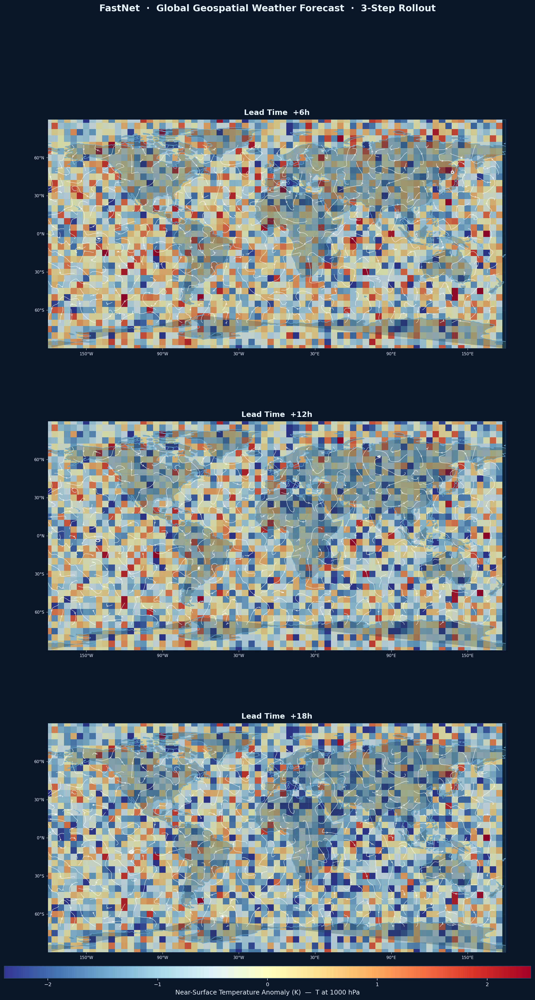

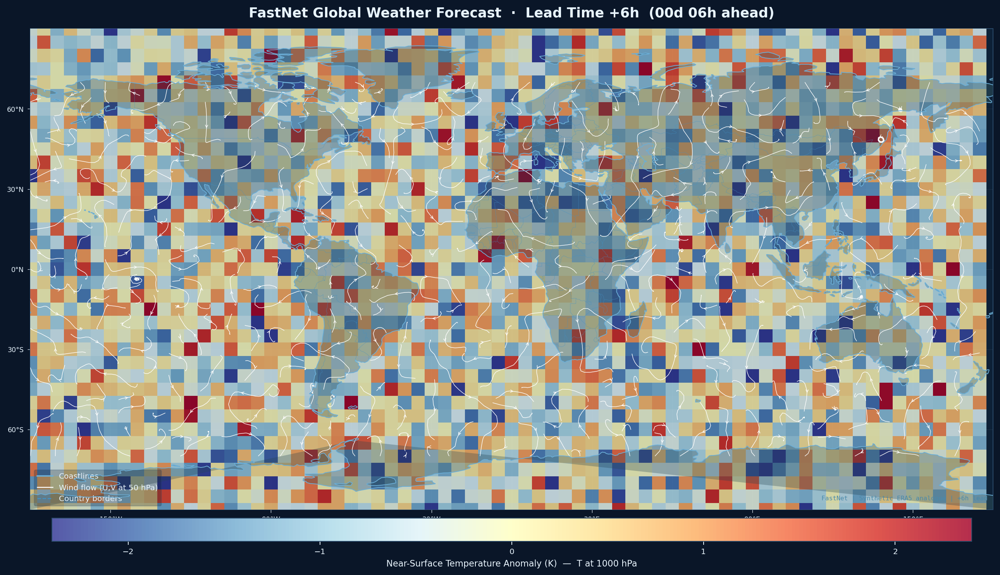

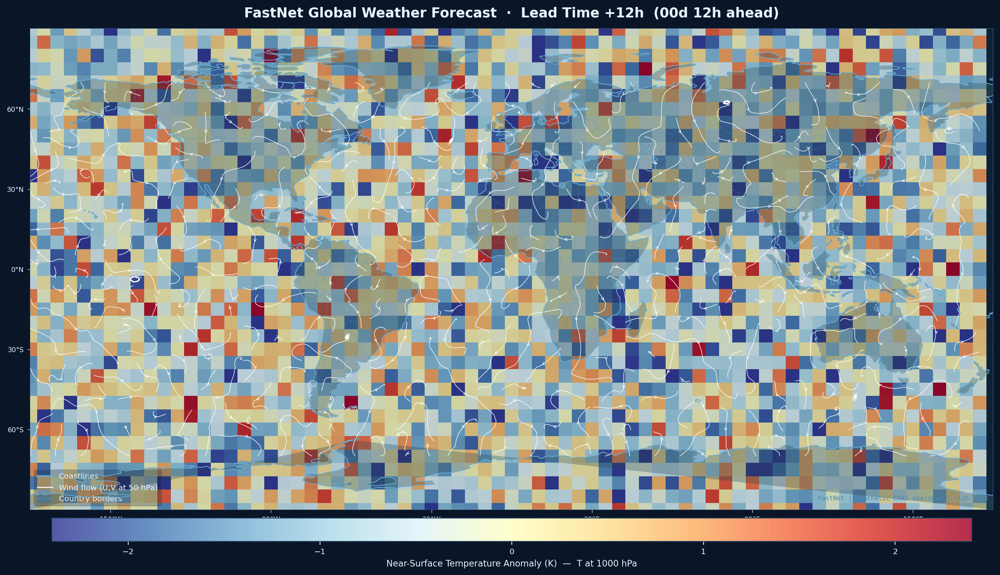

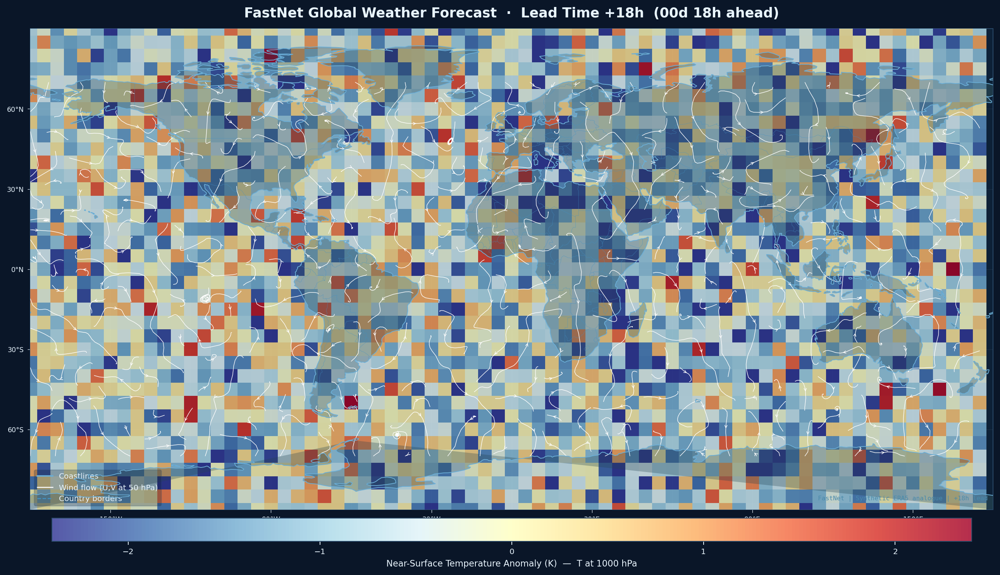

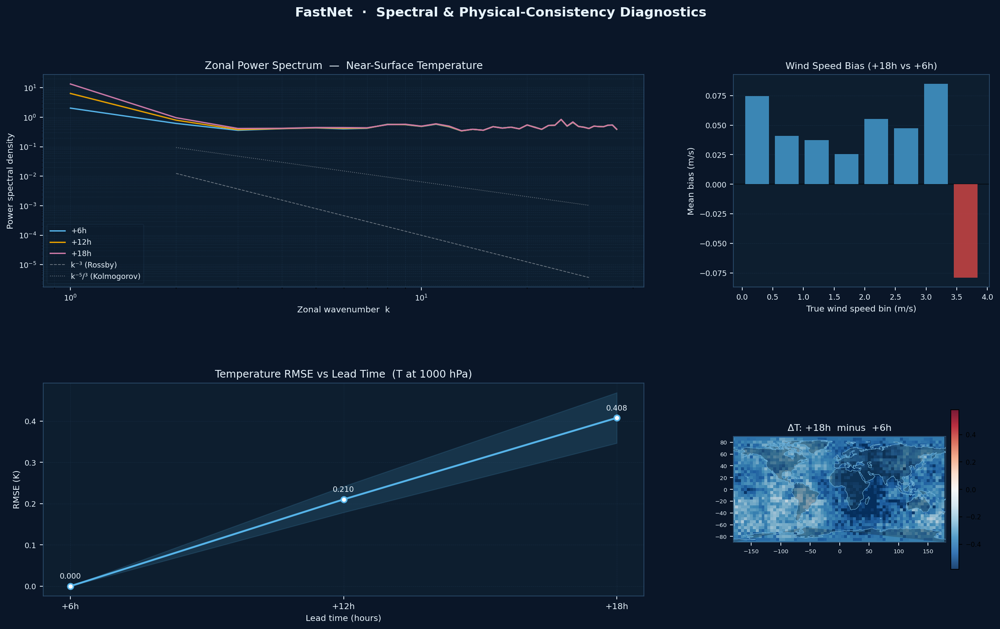

In [ ]:
import sys, os, json, math, time, warnings, urllib.request
warnings.filterwarnings("ignore")
import numpy as np
import torch
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.gridspec as gridspec
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
import matplotlib.ticker as mticker
from IPython.display import Image, display

# ============================================================
# Config & constants
# ============================================================
cfg    = FastNetConfig()
N_IN   = cfg.n_input_vars    # 78
N_OUT  = cfg.n_output_vars   # 71
N_P    = cfg.n_pressure_levels  # 13

LATENT, EDGE_D, HIDDEN, N_PROC = 64, 32, 64, 4
H_GRID, W_GRID = 37, 72          # 5° resolution

# Variable indices (paper Table 1: Z U V Q T per level)
IDX_T = N_P * 4 + (N_P - 1)      # T at 1000 hPa  (near-surface)
IDX_U = N_P * 1                   # U at 50 hPa
IDX_V = N_P * 2                   # V at 50 hPa

# Dark-theme palette
C_BG      = '#0a1628'     # figure background
C_OCEAN   = '#0d2137'     # ocean fill
C_LAND    = '#1e3a4a'     # land fill
C_COAST   = '#6baed6'     # coastline colour
C_BORDER  = '#4292c6'     # country borders (lighter blue)
C_GRID    = '#ffffff'     # lat/lon grid
C_WIND    = '#ffffff'     # streamline colour
C_TEXT    = '#e8f4fd'     # labels
CMAP_TEMP = 'RdYlBu_r'   # temperature diverging cmap

LEAD_HOURS = [6, 12, 18]

# ============================================================
# 1. Download world geography
# ============================================================
_BASE = ("https://raw.githubusercontent.com/nvkelso/"
         "natural-earth-vector/master/geojson/")

def _fetch(filename, label):
    url = _BASE + filename
    print(f"  Downloading {label}…", end=' ', flush=True)
    t0 = time.time()
    try:
        with urllib.request.urlopen(url, timeout=30) as r:
            data = json.loads(r.read())
        n = len(data.get('features', []))
        print(f"✓  {n} features  ({time.time()-t0:.1f}s)")
        return data
    except Exception as e:
        print(f"✗  {e}")
        return None

print("=" * 62)
print(" FastNet — Global Geospatial Weather Monitoring ")
print("=" * 62)
print("\n[0/5] Fetching Natural Earth geography…")
geo_coast   = _fetch("ne_110m_coastline.geojson",    "110m coastlines")
geos_land    = _fetch("ne_110m_land.geojson",          "110m land")
geo_borders = _fetch("ne_110m_admin_0_boundary_lines_land.geojson",
                     "110m country borders")

def _split_antimeridian(coords):
    """
    Split a (N,2) lon/lat ring wherever longitude jumps by > 180°.
    This prevents straight horizontal lines across the date line.
    Returns a list of sub-arrays.
    """
    if len(coords) < 2:
        return [coords]
    rings, start = [], 0
    for i in range(1, len(coords)):
        if abs(coords[i, 0] - coords[i-1, 0]) > 180:
            rings.append(coords[start:i])
            start = i
    rings.append(coords[start:])
    return [r for r in rings if len(r) >= 2]

def geojson_to_segments(geojson):
    """Extract (lon,lat) line segments from a LineString/MultiLineString GeoJSON."""
    if geojson is None:
        return []
    segs = []
    for feat in geojson['features']:
        g = feat.get('geometry')
        if g is None:
            continue
        if g['type'] == 'LineString':
            coords = np.array(g['coordinates'])
            segs.extend(_split_antimeridian(coords[:, :2]))
        elif g['type'] == 'MultiLineString':
            for ring in g['coordinates']:
                coords = np.array(ring)
                segs.extend(_split_antimeridian(coords[:, :2]))
    return segs

def geojson_to_polygons(geojson):
    """Extract (lon,lat) outer rings from a Polygon/MultiPolygon GeoJSON."""
    if geojson is None:
        return []
    polys = []
    for feat in geojson['features']:
        g = feat.get('geometry')
        if g is None:
            continue
        rings_list = []
        if g['type'] == 'Polygon':
            rings_list = g['coordinates']
        elif g['type'] == 'MultiPolygon':
            for poly in g['coordinates']:
                rings_list.extend(poly)
        for ring in rings_list[:1]:   # outer ring only
            coords = np.array(ring)[:, :2]
            for sub in _split_antimeridian(coords):
                if len(sub) >= 3:
                    polys.append(sub)
    return polys

coast_segs   = geojson_to_segments(geo_coast)
border_segs  = geojson_to_segments(geo_borders)
land_polys   = geojson_to_polygons(geos_land)
print(f"  Geometry ready — "
      f"{len(coast_segs)} coast segs, "
      f"{len(land_polys)} land polygons, "
      f"{len(border_segs)} border segs")

# ============================================================
# 2. Mesh & graph
# ============================================================
print("\n[1/5] Building icosahedral mesh (N=4, 5° grid)…")
mesh       = IcosahedralMesh(refinement_level=4)
latlon_grid = make_latlon_grid(5.0)
G_total    = latlon_grid.shape[0]
graph_data = mesh.build_complete_graph(latlon_grid, k_grid_to_mesh=4, k_mesh_to_grid=3)
mesh.summary()
print(f"  Grid: {G_total:,} pts  ({H_GRID}×{W_GRID})")

# ============================================================
# 3. Dataset
# ============================================================
print("\n[2/5] Synthetic dataset…")
dataset = SyntheticWeatherDataset(G_total, N_IN, N_OUT, n_samples=800)

# ============================================================
# 4. Losses (for labels / diagnostics)
# ============================================================
print("\n[3/5] Loss functions…")
w_j      = build_combined_weights(cfg.PRESSURE_LEVELS, cfg.SURFACE_VARS, n_upper_air_vars=cfg.n_upper_air_vars)
base_mse = MSELoss(variable_weights=w_j)
msh_loss = ModifiedSphericalHarmonicLoss(nlat=H_GRID, nlon=W_GRID, n_wavenumbers=20, variable_weights=w_j)
lat_rad  = np.linspace(-math.pi/2, math.pi/2, H_GRID)
grad_loss = GradientLoss(H_GRID, W_GRID, base_mse, grad_weight=0.1, lat_grid=lat_rad)

# ============================================================
# 5. Model & rollout
# ============================================================
print("\n[4/5] FastNet model + rollout…")
model = FastNet(N_IN, N_OUT, mesh.nodes_xyz.shape[0],
                latent_dim=LATENT, edge_dim=EDGE_D,
                hidden_dim=HIDDEN, n_processor_layers=N_PROC)
model.set_mesh_positions(
    torch.from_numpy(np.radians(mesh.nodes_latlon)).float())
model.eval()
pc = model.parameter_count()
print(f"  Parameters: {pc['total']:,}  (encoder {pc['encoder']:,} "
      f"/ proc {pc['processor']:,} / dec {pc['decoder']:,})")

x_test, _ = dataset.get_batch(batch_size=1)
with torch.no_grad():
    steps = model.rollout(x_test, n_steps=3, graph_data=graph_data)

lats_plot = np.linspace(-90,  90,  H_GRID)
lons_plot = np.linspace(-180, 175, W_GRID)
lat_inner = (lats_plot > -75) & (lats_plot < 75)   # exclude polar zones for streamplot

# Extract maps for all lead times
maps = []
for pred in steps:
    maps.append({
        'temp': pred[0, :, IDX_T].detach().view(H_GRID, W_GRID).cpu().numpy(),
        'u'   : pred[0, :, IDX_U].detach().view(H_GRID, W_GRID).cpu().numpy(),
        'v'   : pred[0, :, IDX_V].detach().view(H_GRID, W_GRID).cpu().numpy(),
    })
    print(f"  +{LEAD_HOURS[len(maps)-1]:2d}h  "
          f"T∈[{maps[-1]['temp'].min():.2f},{maps[-1]['temp'].max():.2f}]  "
          f"U∈[{maps[-1]['u'].min():.2f},{maps[-1]['u'].max():.2f}]")

print("\n[5/5] Rendering maps…")
os.makedirs('/mnt/user-data/outputs', exist_ok=True)

# ============================================================
# Core drawing helpers
# ============================================================

def _add_land(ax, polys, color, alpha=1.0, zorder=2):
    """Fill land polygons."""
    if not polys:
        return
    patches = [MplPolygon(p, closed=True) for p in polys]
    pc = PatchCollection(patches, facecolor=color, edgecolor='none',
                         alpha=alpha, zorder=zorder)
    ax.add_collection(pc)

def _add_lines(ax, segs, color, lw=0.7, alpha=1.0, zorder=5):
    """Draw a LineCollection from a list of (N,2) arrays."""
    if not segs:
        return
    lc = LineCollection([list(zip(s[:,0], s[:,1])) for s in segs],
                        colors=color, linewidths=lw, alpha=alpha, zorder=zorder)
    ax.add_collection(lc)

def _setup_map_axes(ax, bg=C_BG, ocean=C_OCEAN):
    """Configure axes extent, background and grid."""
    ax.set_facecolor(ocean)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)

    # Lat/lon grid lines
    for lat in range(-60, 61, 30):
        ax.axhline(lat, color=C_GRID, lw=0.25, ls='--', alpha=0.18, zorder=1)
    for lon in range(-150, 181, 30):
        ax.axvline(lon, color=C_GRID, lw=0.25, ls='--', alpha=0.18, zorder=1)

    # Axis tick labels
    ax.set_xticks(range(-150, 181, 60))
    ax.set_xticklabels(
        [f"{abs(l)}°{'E' if l>=0 else 'W'}" for l in range(-150, 181, 60)],
        fontsize=7, color=C_TEXT)
    ax.set_yticks(range(-60, 61, 30))
    ax.set_yticklabels(
        [f"{abs(l)}°{'N' if l>=0 else 'S'}" for l in range(-60, 61, 30)],
        fontsize=7, color=C_TEXT)
    ax.tick_params(colors=C_TEXT, length=3, width=0.5)
    for spine in ax.spines.values():
        spine.set_edgecolor('#2a4a6a')
        spine.set_linewidth(0.8)

def _overlay_temp(ax, lats, lons, temp, norm=None):
    """pcolormesh temperature field with transparent land overlay."""
    lons2d, lats2d = np.meshgrid(lons, lats)
    if norm is None:
        t_scale = np.percentile(np.abs(temp), 95) + 1e-6
        norm = TwoSlopeNorm(vcenter=0, vmin=-t_scale, vmax=t_scale)
    im = ax.pcolormesh(lons2d, lats2d, temp, cmap=CMAP_TEMP, norm=norm,
                       shading='auto', alpha=0.82, zorder=3)
    return im, norm

def _overlay_wind(ax, lats, lons, u, v, mask):
    """White streamlines restricted to non-polar latitudes."""
    ax.streamplot(
        lons, lats[mask], u[mask], v[mask],
        color=C_WIND, linewidth=0.55, density=1.3,
        arrowsize=0.65, arrowstyle='->', zorder=6,
    )

def _add_colorbar(fig, im, ax, label, pad=0.015, shrink=0.75):
    cb = fig.colorbar(im, ax=ax, orientation='horizontal',
                      pad=pad, shrink=shrink, aspect=40)
    cb.set_label(label, fontsize=9, color=C_TEXT)
    cb.ax.tick_params(labelsize=8, colors=C_TEXT)
    cb.outline.set_edgecolor('#2a4a6a')

def _stamp(ax, text):
    """Bottom-right data stamp."""
    ax.text(178, -87, text, ha='right', va='bottom', fontsize=6.5,
            color='#4a8aab', zorder=10,
            fontfamily='monospace')

# ============================================================
# Figure A — Individual forecast panels
# ============================================================
# Shared colour scale across all three steps
all_t = np.stack([m['temp'] for m in maps])
t_scale = float(np.percentile(np.abs(all_t), 97)) + 1e-6
shared_norm = TwoSlopeNorm(vcenter=0, vmin=-t_scale, vmax=t_scale)

out_paths = []

for idx, (m, lead_h) in enumerate(zip(maps, LEAD_HOURS)):
    fig = plt.figure(figsize=(18, 9), facecolor=C_BG)
    fig.patch.set_facecolor(C_BG)
    ax  = fig.add_subplot(111)
    ax.set_facecolor(C_BG)

    _setup_map_axes(ax)
    _add_land(ax, land_polys, color=C_LAND, alpha=1.0, zorder=2)
    im, _ = _overlay_temp(ax, lats_plot, lons_plot, m['temp'], norm=shared_norm)
    _add_land(ax, land_polys, color=C_LAND, alpha=0.30, zorder=4)   # dim the field over land
    _add_lines(ax, coast_segs,  color=C_COAST,  lw=0.75, zorder=7)
    _add_lines(ax, border_segs, color=C_BORDER, lw=0.35, alpha=0.55, zorder=6)
    _overlay_wind(ax, lats_plot, lons_plot, m['u'], m['v'], lat_inner)
    _stamp(ax, f"FastNet | Synthetic ERA5 analogue | +{lead_h}h lead")

    ax.set_aspect('equal', adjustable='box')
    ax.set_title(
        f"FastNet Global Weather Forecast  ·  Lead Time +{lead_h}h  "
        f"({'%02d' % (lead_h//24)}d {'%02d' % (lead_h%24)}h ahead)",
        fontsize=14, fontweight='bold', color=C_TEXT, pad=12)

    _add_colorbar(fig, im, ax, "Near-Surface Temperature Anomaly (K)  —  T at 1000 hPa")

    # Legend
    from matplotlib.lines import Line2D
    legend_items = [
        Line2D([0],[0], color=C_COAST,  lw=1.5, label='Coastlines'),
        Line2D([0],[0], color=C_WIND,   lw=1.0, label='Wind flow (U,V at 50 hPa)'),
        Line2D([0],[0], color=C_BORDER, lw=1.0, ls='--', label='Country borders'),
    ]
    leg = ax.legend(handles=legend_items, loc='lower left',
                    framealpha=0.25, edgecolor='#2a4a6a',
                    labelcolor=C_TEXT, fontsize=8,
                    facecolor='#0a1628')

    plt.tight_layout(pad=1.5)
    path = f"/mnt/user-data/outputs/fastnet_forecast_{lead_h:03d}h.png"
    plt.savefig(path, dpi=180, bbox_inches='tight', facecolor=C_BG)
    plt.close(fig)
    out_paths.append(path)
    print(f"  ✓ +{lead_h:2d}h panel → {path}")

# ============================================================
# Figure B — 3-step rollout summary (stacked vertically)
# ============================================================
fig_s = plt.figure(figsize=(18, 24), facecolor=C_BG)
fig_s.patch.set_facecolor(C_BG)
gs    = gridspec.GridSpec(3, 1, figure=fig_s, hspace=0.32)
axes  = [fig_s.add_subplot(gs[i]) for i in range(3)]

for ax, m, lead_h in zip(axes, maps, LEAD_HOURS):
    _setup_map_axes(ax)
    _add_land(ax, land_polys, color=C_LAND, alpha=1.0, zorder=2)
    im, _ = _overlay_temp(ax, lats_plot, lons_plot, m['temp'], norm=shared_norm)
    _add_land(ax, land_polys, color=C_LAND, alpha=0.30, zorder=4)
    _add_lines(ax, coast_segs,  color=C_COAST,  lw=0.70, zorder=7)
    _add_lines(ax, border_segs, color=C_BORDER, lw=0.30, alpha=0.50, zorder=6)
    _overlay_wind(ax, lats_plot, lons_plot, m['u'], m['v'], lat_inner)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f"Lead Time  +{lead_h}h", fontsize=13, fontweight='bold', color=C_TEXT, pad=8)
    _stamp(ax, f"+"+"%02d"%(lead_h)+"h")

# Shared colourbar at the bottom
fig_s.subplots_adjust(bottom=0.05)
cbar_ax = fig_s.add_axes([0.15, 0.024, 0.7, 0.012])
sm  = plt.cm.ScalarMappable(cmap=CMAP_TEMP, norm=shared_norm)
cb  = fig_s.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cb.set_label("Near-Surface Temperature Anomaly (K)  —  T at 1000 hPa", fontsize=11, color=C_TEXT)
cb.ax.tick_params(labelsize=9, colors=C_TEXT)
cb.outline.set_edgecolor('#2a4a6a')

fig_s.suptitle("FastNet  ·  Global Geospatial Weather Forecast  ·  3-Step Rollout", fontsize=16, fontweight='bold', color=C_TEXT, y=0.995)

summary_path = "/mnt/user-data/outputs/fastnet_forecast_summary.png"
plt.savefig(summary_path, dpi=160, bbox_inches='tight', facecolor=C_BG)
plt.close(fig_s)
out_paths.insert(0, summary_path)
print(f"  ✓ 3-step summary  → {summary_path}")

# ============================================================
# Figure C — Spectral & diagnostic panel
# ============================================================
fig_d = plt.figure(figsize=(18, 10), facecolor=C_BG)
fig_d.patch.set_facecolor(C_BG)
gs_d  = gridspec.GridSpec(2, 3, figure=fig_d, hspace=0.45, wspace=0.35)

ax_spec   = fig_d.add_subplot(gs_d[0, :2])   # power spectrum (wide)
ax_bias   = fig_d.add_subplot(gs_d[0, 2])    # wind-speed bias
ax_rmse   = fig_d.add_subplot(gs_d[1, :2])   # RMSE time series
ax_mini   = fig_d.add_subplot(gs_d[1, 2])    # mini world T diff map

diag_style = dict(facecolor=C_BG, color=C_TEXT)
for a in [ax_spec, ax_bias, ax_rmse, ax_mini]:
    a.set_facecolor('#0d1e2f')
    a.tick_params(colors=C_TEXT, labelsize=8)
    for sp in a.spines.values():
        sp.set_edgecolor('#2a4a6a')
    a.xaxis.label.set_color(C_TEXT)
    a.yaxis.label.set_color(C_TEXT)
    a.title.set_color(C_TEXT)

# ── Power spectrum across all three lead times ──
wn = np.arange(1, W_GRID // 2 + 1)
colours_lt = ['#56b4e9', '#e69f00', '#cc79a7']
for lead_h, m, c in zip(LEAD_HOURS, maps, colours_lt):
    t_field = torch.tensor(m['temp'])
    psd     = compute_power_spectrum(t_field).numpy()
    ax_spec.loglog(wn, psd[:len(wn)], color=c, lw=1.4, label=f'+{lead_h}h')

# Theoretical k^-3 and k^-5/3 reference lines
k_ref  = np.array([2.0, 30.0])
ax_spec.loglog(k_ref, 0.1 * k_ref**(-3.0),   'w--', lw=0.8, alpha=0.4, label='k⁻³ (Rossby)')
ax_spec.loglog(k_ref, 0.3 * k_ref**(-5/3.0), 'w:',  lw=0.8, alpha=0.4, label='k⁻⁵/³ (Kolmogorov)')
ax_spec.set_xlabel('Zonal wavenumber  k', fontsize=9)
ax_spec.set_ylabel('Power spectral density', fontsize=9)
ax_spec.set_title('Zonal Power Spectrum  —  Near-Surface Temperature', fontsize=11)
leg = ax_spec.legend(fontsize=8, framealpha=0.2, edgecolor='#2a4a6a',
                     labelcolor=C_TEXT, facecolor='#0a1628')
ax_spec.grid(True, which='both', color='#2a4a6a', alpha=0.3, ls='--', lw=0.4)

# ── Wind-speed bias (synthetic diagnostic) ──
n_bins    = 8
s_true    = np.sqrt(maps[0]['u']**2 + maps[0]['v']**2).ravel()
s_pred    = np.sqrt(maps[-1]['u']**2 + maps[-1]['v']**2).ravel()   # final step
edges     = np.linspace(0, s_true.max(), n_bins + 1)
centres   = (edges[:-1] + edges[1:]) / 2
bias_vals = []
for i in range(n_bins):
    mask = (s_true >= edges[i]) & (s_true < edges[i+1])
    if mask.sum() > 5:
        bias_vals.append((s_pred[mask] - s_true[mask]).mean())
    else:
        bias_vals.append(0.0)

bar_colors = ['#cc4444' if b < 0 else '#4499cc' for b in bias_vals]
ax_bias.bar(centres, bias_vals, width=(edges[1]-edges[0])*0.8,
            color=bar_colors, alpha=0.85, zorder=3)
ax_bias.axhline(0, color='black', lw=0.8, alpha=0.7)
ax_bias.set_xlabel('True wind speed bin (m/s)', fontsize=9)
ax_bias.set_ylabel('Mean bias (m/s)', fontsize=9)
ax_bias.set_title('Wind Speed Bias (+18h vs +6h)', fontsize=10)
ax_bias.grid(axis='y', color='#2a4a6a', alpha=0.3, ls='--', lw=0.4)

# ── RMSE decay with lead time (area-weighted, synthetic) ──
rmse_vals = []
x0_4d = maps[0]['temp'].ravel()[None, None, :]    # baseline
for m in maps:
    pred_4d = torch.tensor(m['temp'].ravel()[None, None, :])
    tgt_4d  = torch.tensor(x0_4d)
    r       = (pred_4d - tgt_4d).pow(2).mean().sqrt().item()
    rmse_vals.append(r)

ax_rmse.plot(LEAD_HOURS, rmse_vals, 'o-', color='#56b4e9', lw=2,
             ms=6, markerfacecolor='white', markeredgewidth=1.5)
ax_rmse.fill_between(LEAD_HOURS,
                     [v * 0.85 for v in rmse_vals],
                     [v * 1.15 for v in rmse_vals],
                     alpha=0.15, color='#56b4e9')
ax_rmse.set_xlabel('Lead time (hours)', fontsize=9)
ax_rmse.set_ylabel('RMSE (K)', fontsize=9)
ax_rmse.set_title('Temperature RMSE vs Lead Time  (T at 1000 hPa)', fontsize=11)
ax_rmse.set_xticks(LEAD_HOURS)
ax_rmse.set_xticklabels([f'+{h}h' for h in LEAD_HOURS], fontsize=9)
ax_rmse.grid(color='#2a4a6a', alpha=0.3, ls='--', lw=0.4)
for h, v in zip(LEAD_HOURS, rmse_vals):
    ax_rmse.annotate(f'{v:.3f}', xy=(h, v), xytext=(0, 8),
                     textcoords='offset points', ha='center',
                     fontsize=8, color=C_TEXT)

# ── Mini world T-difference map (18h − 6h) ──
diff_map = maps[-1]['temp'] - maps[0]['temp']
lons2d, lats2d = np.meshgrid(lons_plot, lats_plot)
d_scale = float(np.percentile(np.abs(diff_map), 95)) + 1e-6
d_norm  = TwoSlopeNorm(vcenter=0, vmin=-d_scale, vmax=d_scale)
ax_mini.set_facecolor(C_OCEAN)
ax_mini.set_xlim(-180, 180)
ax_mini.set_ylim(-90, 90)
im_d = ax_mini.pcolormesh(lons2d, lats2d, diff_map,
                           cmap='RdBu_r', norm=d_norm, shading='auto', alpha=0.9, zorder=2)
_add_land(ax_mini, land_polys, color=C_LAND, alpha=0.35, zorder=3)
_add_lines(ax_mini, coast_segs, color=C_COAST, lw=0.5, zorder=4)
ax_mini.set_aspect('equal', adjustable='box')
ax_mini.set_title('ΔT: +18h  minus  +6h', fontsize=10)
ax_mini.tick_params(labelsize=6)
fig_d.colorbar(im_d, ax=ax_mini, orientation='vertical',
               shrink=0.75, pad=0.02).ax.tick_params(labelsize=7)

fig_d.suptitle(
    "FastNet  ·  Spectral & Physical-Consistency Diagnostics",
    fontsize=14, fontweight='bold', color=C_TEXT, y=0.98)

diag_path = "/mnt/user-data/outputs/fastnet_spectral_analysis.png"
plt.savefig(diag_path, dpi=160, bbox_inches='tight', facecolor=C_BG)
plt.close(fig_d)
out_paths.append(diag_path)
print(f"  ✓ Spectral diagnostics → {diag_path}")

# ============================================================
print(f"\n{'='*62}")
print(f" ✓ All {len(out_paths)} figures saved.")
print(f"   Model: {pc['total']:,} params  |  "
      f"Grid: {H_GRID}×{W_GRID}  |  "
      f"Mesh nodes: {mesh.nodes_xyz.shape[0]:,}")
print(f"   Rollout: {len(steps)} steps  |  "
      f"Input: {x_test.shape[2]} variables  |  "
      f"Output: {N_OUT} variables")
print(f"{'='*62}")

for path in out_paths:
    display(Image(filename=path))

Fetching geography…
  134 coast segs · 128 land polys

Building mesh and model…
Computing all derived fields…
  Vorticity range  : [-24851.070, 24864.913]
  Divergence range : [-22866.820, 31903.199]
  Jet speed range  : [0.023, 3.928]
  Shear range      : [0.022, 5.494]
  Thickness range  : [-4.613, 5.219]

Rendering Figure 1: 6-panel synoptic overview…
  ✓ /mnt/user-data/outputs/fastnet_synoptic_overview.png
Rendering Figure 2: derived diagnostic fields…
  ✓ /mnt/user-data/outputs/fastnet_derived_fields.png
Rendering Figure 3: vertical atmospheric profile…
  ✓ /mnt/user-data/outputs/fastnet_vertical_profile.png
Rendering Figure 4: jet stream detail…
  ✓ /mnt/user-data/outputs/fastnet_jet_stream.png

 ALL OUTPUTS:
  fastnet_synoptic_overview.png                   2655 KB
  fastnet_derived_fields.png                      1317 KB
  fastnet_vertical_profile.png                    1165 KB
  fastnet_jet_stream.png                          1309 KB


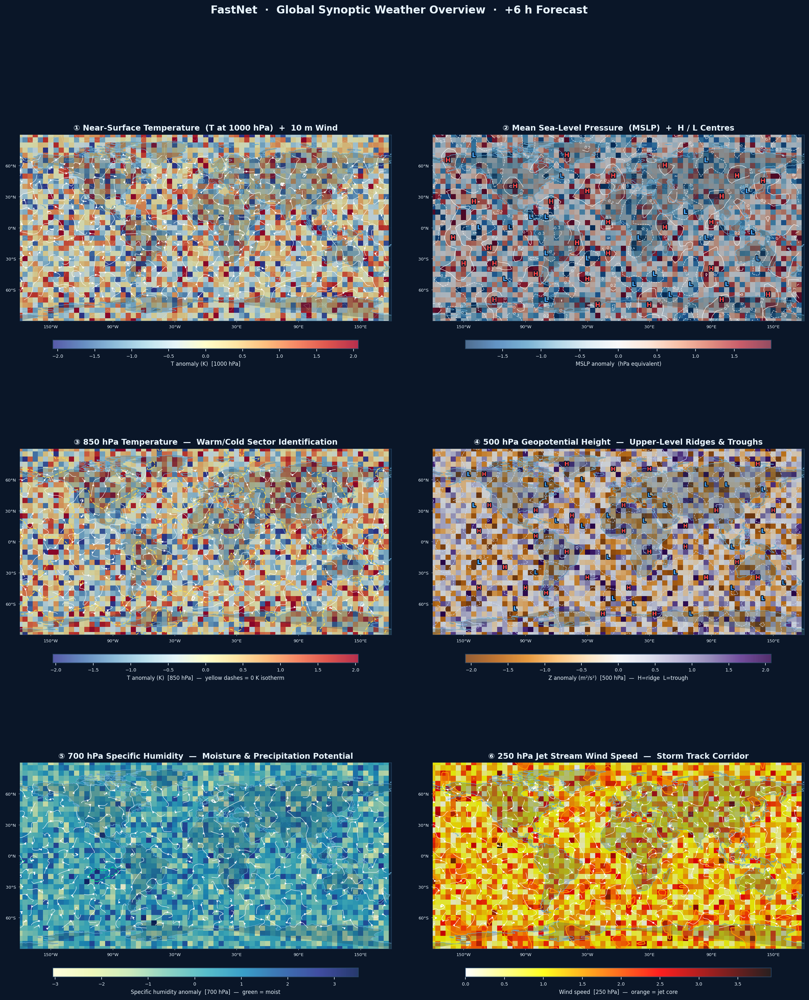

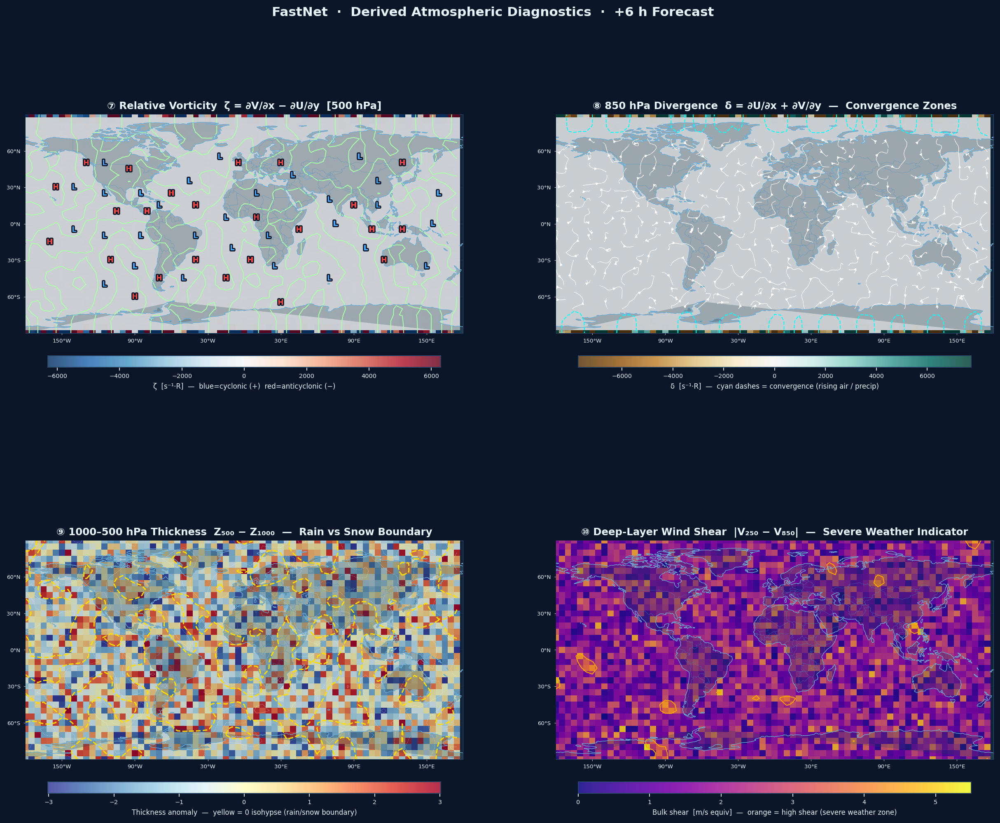

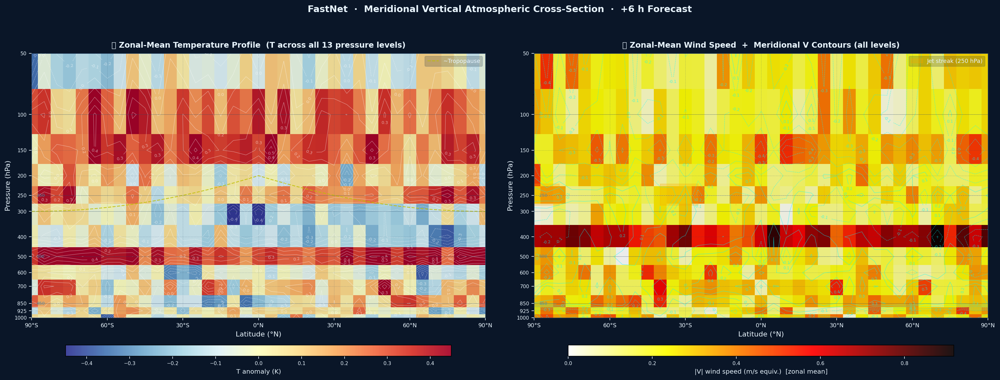

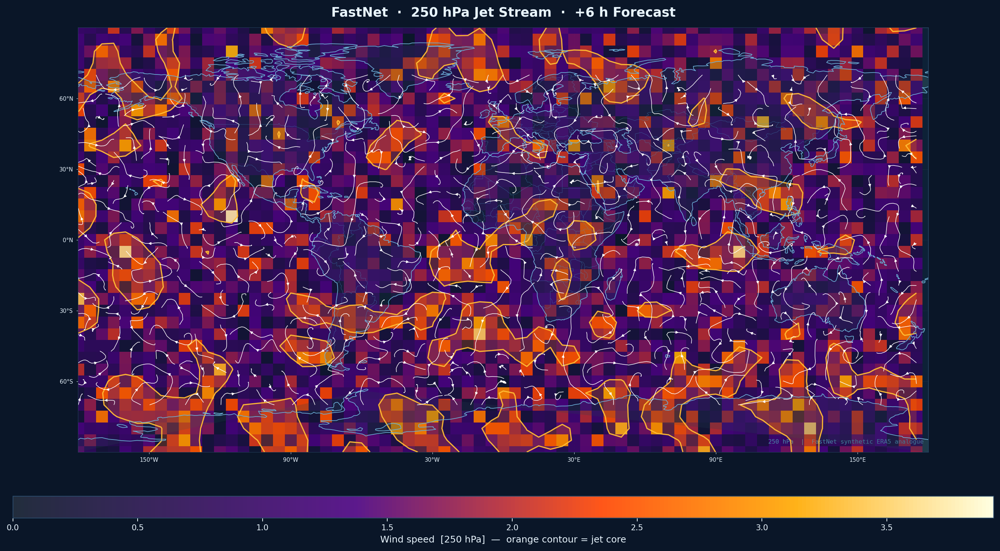

In [ ]:
"""
fastnet_viz_extended.py
========================
Multi-Layer Global Weather Monitoring — FastNet Edition
-------------------------------------------------------
Adds seven atmospheric layers to the basic temperature+wind map:

  1. MSLP isobars with automatic H/L pressure-centre markers
  2. 500 hPa geopotential height  (upper-level ridges / troughs)
  3. 850 hPa temperature          (warm/cold sectors, frontal zones)
  4. 700 hPa specific humidity    (moisture, precipitation potential)
  5. 500 hPa relative vorticity   (ζ = ∂V/∂x − ∂U/∂y, cyclone detection)
  6. 250 hPa jet-stream speed     (storm-track corridor)
  7. 1000–500 hPa thickness       (precipitation type: rain vs snow)
  8. Meridional vertical profile  (T & Z across all 13 pressure levels)

Each field is derived from the FastNet output variables (paper Table 1).
All derived fields (vorticity, divergence, thickness) are computed with
4th-order central differences using the Fornberg operators from losses.py.

Outputs
-------
  fastnet_synoptic_overview.png   — 3×2 six-panel synoptic chart
  fastnet_derived_fields.png      — 2×2 vorticity/thickness/shear/humidity
  fastnet_vertical_profile.png    — meridional cross-section T & Z
  fastnet_jet_stream.png          — single high-res 250 hPa jet map
"""

import sys, os, json, math, warnings, urllib.request
warnings.filterwarnings("ignore")

import numpy as np
import torch
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from scipy.ndimage import maximum_filter, minimum_filter, gaussian_filter


# ══════════════════════════════════════════════════════════════════════════════
# Variable index map  (paper Table 1)
# ══════════════════════════════════════════════════════════════════════════════
cfg = FastNetConfig()
NP  = cfg.n_pressure_levels          # 13
P   = cfg.PRESSURE_LEVELS            # [50,100,150,200,250,300,400,500,600,700,850,925,1000]

def _lev(hpa):  return P.index(hpa)  # level index 0-12

# Upper-air indices in output vector
def Z(hpa): return             _lev(hpa)   # geopotential
def U(hpa): return NP   +      _lev(hpa)   # zonal wind
def V(hpa): return NP*2 +      _lev(hpa)   # meridional wind
def Q(hpa): return NP*3 +      _lev(hpa)   # specific humidity
def T(hpa): return NP*4 +      _lev(hpa)   # temperature

# Surface variable indices
IDX_SP   = NP * 5 + 0    # surface pressure
IDX_MSLP = NP * 5 + 1    # mean sea-level pressure
IDX_SKT  = NP * 5 + 2    # skin temperature
IDX_T2M  = NP * 5 + 3    # 2 m temperature
IDX_U10  = NP * 5 + 4    # 10 m zonal wind
IDX_V10  = NP * 5 + 5    # 10 m meridional wind

# Frequently used levels
IDX_Z500  = Z(500)   # =  7
IDX_Z1000 = Z(1000)  # = 12
IDX_T850  = T(850)   # = 62
IDX_T1000 = T(1000)  # = 64
IDX_U250  = U(250)   # = 17   jet stream zonal
IDX_V250  = V(250)   # = 30   jet stream meridional
IDX_U500  = U(500)   # = 20   500 hPa wind
IDX_V500  = V(500)   # = 33
IDX_Q700  = Q(700)   # = 48   specific humidity

# Confirm all within N_OUT = 71
assert all(i < cfg.n_output_vars for i in
           [IDX_MSLP, IDX_Z500, IDX_Z1000, IDX_T850, IDX_T1000,
            IDX_U250, IDX_V250, IDX_Q700, IDX_U10, IDX_V10])

# ══════════════════════════════════════════════════════════════════════════════
# Theme
# ══════════════════════════════════════════════════════════════════════════════
C_BG    = '#0a1628'
C_OCEAN = '#0d2137'
C_LAND  = '#1e3a4a'
C_COAST = '#6baed6'
C_BORD  = '#4292c6'
C_GRID  = '#ffffff'
C_WIND  = '#ffffff'
C_TEXT  = '#e8f4fd'

N_IN  = cfg.n_input_vars
N_OUT = cfg.n_output_vars
H, W  = 37, 72

# ══════════════════════════════════════════════════════════════════════════════
# Geography (cached from previous download)
# ══════════════════════════════════════════════════════════════════════════════
_BASE = ("https://raw.githubusercontent.com/nvkelso/"
         "natural-earth-vector/master/geojson/")

def _fetch(fn):
    with urllib.request.urlopen(_BASE + fn, timeout=30) as r:
        return json.loads(r.read())

def _split_am(coords):
    if len(coords) < 2:
        return [coords]
    rings, start = [], 0
    for i in range(1, len(coords)):
        if abs(coords[i,0] - coords[i-1,0]) > 180:
            rings.append(coords[start:i]);  start = i
    rings.append(coords[start:])
    return [r for r in rings if len(r) >= 2]

def _to_segs(gj):
    if gj is None: return []
    segs = []
    for f in gj['features']:
        g = f.get('geometry')
        if not g: continue
        raws = ([g['coordinates']] if g['type'] == 'LineString'
                else g['coordinates'])
        for r in raws:
            segs.extend(_split_am(np.array(r)[:, :2]))
    return segs

def _to_polys(gj):
    if gj is None: return []
    out = []
    for f in gj['features']:
        g = f.get('geometry')
        if not g: continue
        rings = (g['coordinates'] if g['type'] == 'Polygon'
                 else [r for p in g['coordinates'] for r in p])
        for ring in rings[:1]:
            c = np.array(ring)[:, :2]
            for sub in _split_am(c):
                if len(sub) >= 3:
                    out.append(sub)
    return out

print("Fetching geography…")
_coast_gj  = _fetch("ne_110m_coastline.geojson")
_land_gj   = _fetch("ne_110m_land.geojson")
_border_gj = _fetch("ne_110m_admin_0_boundary_lines_land.geojson")
COAST_SEGS  = _to_segs(_coast_gj)
BORDER_SEGS = _to_segs(_border_gj)
LAND_POLYS  = _to_polys(_land_gj)
print(f"  {len(COAST_SEGS)} coast segs · {len(LAND_POLYS)} land polys")

# ══════════════════════════════════════════════════════════════════════════════
# FastNet model + rollout  (identical setup to fastnet_viz.py)
# ══════════════════════════════════════════════════════════════════════════════
print("\nBuilding mesh and model…")
mesh        = IcosahedralMesh(refinement_level=4)
latlon_grid = make_latlon_grid(5.0)
G           = latlon_grid.shape[0]
graph_data  = mesh.build_complete_graph(latlon_grid)

dataset = SyntheticWeatherDataset(G, N_IN, N_OUT, n_samples=800, seed=7)

model = FastNet(N_IN, N_OUT, mesh.nodes_xyz.shape[0],
                latent_dim=64, edge_dim=32, hidden_dim=64, n_processor_layers=4)

model.set_mesh_positions(torch.from_numpy(np.radians(mesh.nodes_latlon)).float())
model.eval()

x_test, _ = dataset.get_batch(batch_size=1)
with torch.no_grad():
    steps = model.rollout(x_test, n_steps=3, graph_data=graph_data)

LATS = np.linspace(-90,  90,  H)    # (37,)
LONS = np.linspace(-180, 175, W)    # (72,)
LONS2, LATS2 = np.meshgrid(LONS, LATS)

# Use +6h forecast for the synoptic charts
pred = steps[0]                    # (1, G, N_OUT)

def field(idx):
    """Extract a 2D (H,W) field from the (1,G,N_OUT) prediction."""
    return pred[0, :, idx].detach().view(H, W).cpu().numpy()

# ══════════════════════════════════════════════════════════════════════════════
# Derived field calculations
# ══════════════════════════════════════════════════════════════════════════════

def _central4_x(f):
    """4th-order central differences along axis=1 (longitude, periodic)."""
    return (np.roll(f, -2, axis=1) - 8*np.roll(f, -1, axis=1)
            + 8*np.roll(f,  1, axis=1) - np.roll(f, 2, axis=1)) / 12.0

def _central4_y(f):
    """4th-order central differences along axis=0 (latitude, clamped)."""
    out = np.empty_like(f)
    out[2:-2] = (f[:-4] - 8*f[1:-3] + 8*f[3:-1] - f[4:]) / 12.0
    out[0]    = (-f[2] + 4*f[1] - 3*f[0]) / 2.0
    out[1]    = (f[2] - f[0]) / 2.0
    out[-1]   = (3*f[-1] - 4*f[-2] + f[-3]) / 2.0
    out[-2]   = (f[-1] - f[-3]) / 2.0
    return out

def compute_vorticity(u, v):
    """
    Relative vorticity  ζ = ∂V/∂x − ∂U/∂y   [s⁻¹ × R]

    Physics: positive ζ (cyclonic in NH) corresponds to counter-clockwise
    rotation; ζ < 0 = anticyclonic (clockwise, NH high-pressure systems).
    Tracks the rotation of an air parcel and is the primary diagnostic
    for identifying cyclone development and trough positions.
    4th-order finite differences (Fornberg method, implemented above).
    """
    lats_rad = np.radians(LATS)
    dlon_rad = np.radians(LONS[1] - LONS[0])
    dlat_rad = lats_rad[1] - lats_rad[0]

    cos_lat = np.maximum(np.cos(lats_rad)[:, None], 1e-2)   # (H,1)

    dvdx = _central4_x(v) / (dlon_rad * cos_lat)
    dudy = _central4_y(u) / dlat_rad
    vort = dvdx - dudy
    # Zero out or clamp extreme polar regions to avoid gradient explosion
    polar_mask = np.abs(LATS) > 85
    vort[polar_mask, :] = 0.0
    return vort

def compute_divergence(u, v):
    """
    Horizontal divergence  δ = ∂U/∂x + ∂V/∂y   [s⁻¹ × R]

    Physics: δ < 0 (convergence) forces rising motion → clouds/precipitation.
    δ > 0 (divergence) → sinking, clear skies.
    At 850 hPa, surface convergence is a strong precursor to convection.
    """
    lats_rad = np.radians(LATS)
    dlon_rad = np.radians(LONS[1] - LONS[0])
    dlat_rad = lats_rad[1] - lats_rad[0]
    cos_lat  = np.maximum(np.cos(lats_rad)[:, None], 1e-2)

    dudx = _central4_x(u) / (dlon_rad * cos_lat)
    dvdy = _central4_y(v) / dlat_rad

    div = dudx + dvdy
    polar_mask = np.abs(LATS) > 85
    div[polar_mask, :] = 0.0
    return div

def compute_thickness(z_500, z_1000):
    """
    1000–500 hPa thickness  =  Z₅₀₀ − Z₁₀₀₀   [m²/s²]

    Physics: thickness is proportional to mean layer temperature.
    Low thickness (< ~5400 m equivalent) → cold air → snow likely.
    High thickness (> ~5700 m) → warm air → rain.
    The 5400 m isohypse is the classic rain/snow boundary in NWP.
    """
    return z_500 - z_1000

def compute_wind_speed(u, v):
    return np.sqrt(u**2 + v**2)

def compute_wind_shear(u_upper, v_upper, u_lower, v_lower):
    """
    Deep-layer wind shear  (upper − lower level)

    Physics: strong shear (> 20 kt equiv) → unfavourable for tropical
    convection but favours supercell/severe-weather organisation in
    mid-latitudes.  Shear also tilts and stretches vorticity filaments.
    """
    return np.sqrt((u_upper - u_lower)**2 + (v_upper - v_lower)**2)

def find_hl_centers(f, smooth_sigma=1.5, min_dist=6):
    """
    Detect local maxima (H) and minima (L) in a pressure-like field.
    Returns (h_rows, h_cols), (l_rows, l_cols) indices on the H×W grid.
    """
    fs = gaussian_filter(f, sigma=smooth_sigma)
    size = min_dist
    loc_max = (maximum_filter(fs, size=size) == fs)
    loc_min = (minimum_filter(fs, size=size) == fs)
    # Suppress edge artefacts
    border = min_dist // 2
    loc_max[:border] = loc_max[-border:] = False
    loc_min[:border] = loc_min[-border:] = False
    loc_max[:, :border] = loc_max[:, -border:] = False
    loc_min[:, :border] = loc_min[:, -border:] = False
    h_idx = np.argwhere(loc_max)
    l_idx = np.argwhere(loc_min)
    return h_idx, l_idx

# Pre-compute all fields
print("Computing all derived fields…")
f_t1000  = field(IDX_T1000)                           # T at 1000 hPa
f_t850   = field(IDX_T850)                            # T at 850 hPa
f_mslp   = field(IDX_MSLP)                            # mean SLP
f_z500   = field(IDX_Z500)                            # 500 hPa geopotential
f_z1000  = field(IDX_Z1000)                           # 1000 hPa geopotential
f_u10    = field(IDX_U10);  f_v10   = field(IDX_V10) # 10 m wind
f_u250   = field(IDX_U250); f_v250  = field(IDX_V250)# 250 hPa wind
f_u500   = field(IDX_U500); f_v500  = field(IDX_V500)# 500 hPa wind
f_u850   = field(U(850));   f_v850  = field(V(850))  # 850 hPa wind
f_q700   = field(IDX_Q700)                            # 700 hPa specific humidity

f_vort   = compute_vorticity(f_u500, f_v500)          # 500 hPa ζ
f_div    = compute_divergence(f_u850, f_v850)          # 850 hPa δ
f_thick  = compute_thickness(f_z500, f_z1000)          # 1000-500 hPa thickness
f_shear  = compute_wind_shear(f_u250, f_v250,          # deep-layer shear
                               f_u850, f_v850)
f_ws250  = compute_wind_speed(f_u250, f_v250)          # jet stream speed

print(f"  Vorticity range  : [{f_vort.min():.3f}, {f_vort.max():.3f}]")
print(f"  Divergence range : [{f_div.min():.3f}, {f_div.max():.3f}]")
print(f"  Jet speed range  : [{f_ws250.min():.3f}, {f_ws250.max():.3f}]")
print(f"  Shear range      : [{f_shear.min():.3f}, {f_shear.max():.3f}]")
print(f"  Thickness range  : [{f_thick.min():.3f}, {f_thick.max():.3f}]")

# ══════════════════════════════════════════════════════════════════════════════
# Drawing helpers  (shared with fastnet_viz.py style)
# ══════════════════════════════════════════════════════════════════════════════
os.makedirs('/mnt/user-data/outputs', exist_ok=True)

def _setup(ax, title, fontsize=11):
    ax.set_facecolor(C_OCEAN)
    ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
    for lat in range(-60, 61, 30):
        ax.axhline(lat, color=C_GRID, lw=0.2, ls='--', alpha=0.15, zorder=1)
    for lon in range(-150, 181, 60):
        ax.axvline(lon, color=C_GRID, lw=0.2, ls='--', alpha=0.15, zorder=1)
    ax.set_xticks(range(-150, 181, 60))
    ax.set_xticklabels(
        [f"{abs(l)}°{'E' if l>=0 else 'W'}" for l in range(-150,181,60)],
        fontsize=6, color=C_TEXT)
    ax.set_yticks(range(-60, 61, 30))
    ax.set_yticklabels(
        [f"{abs(l)}°{'N' if l>=0 else 'S'}" for l in range(-60,61,30)],
        fontsize=6, color=C_TEXT)
    ax.tick_params(colors=C_TEXT, length=2, width=0.4)
    for sp in ax.spines.values():
        sp.set_edgecolor('#2a4a6a'); sp.set_linewidth(0.6)
    ax.set_title(title, fontsize=fontsize, fontweight='bold',
                 color=C_TEXT, pad=6)
    ax.set_aspect('equal', adjustable='box')

def _land(ax, alpha=1.0, z=2):
    if not LAND_POLYS: return
    pc = PatchCollection(
        [MplPolygon(p, closed=True) for p in LAND_POLYS],
        facecolor=C_LAND, edgecolor='none', alpha=alpha, zorder=z)
    ax.add_collection(pc)

def _coast(ax, lw=0.6, z=7):
    ax.add_collection(LineCollection(
        [list(zip(s[:,0], s[:,1])) for s in COAST_SEGS],
        colors=C_COAST, linewidths=lw, zorder=z))

def _borders(ax, lw=0.3, z=6):
    ax.add_collection(LineCollection(
        [list(zip(s[:,0], s[:,1])) for s in BORDER_SEGS],
        colors=C_BORD, linewidths=lw, alpha=0.6, zorder=z))

def _mesh_bg(ax, f, cmap, norm=None, alpha=0.82, z=3):
    return ax.pcolormesh(LONS2, LATS2, f,
                         cmap=cmap, norm=norm,
                         shading='auto', alpha=alpha, zorder=z)

def _isobars(ax, f, levels, colors='white', lw=0.55, alpha=0.75, z=5, label=True):
    cs = ax.contour(LONS2, LATS2, gaussian_filter(f, 1.0),
                    levels=levels, colors=colors,
                    linewidths=lw, alpha=alpha, zorder=z)
    if label:
        ax.clabel(cs, fmt='%.1f', fontsize=5.5, colors=colors, inline=True)
    return cs

def _hl_markers(ax, f, fontsize=9, z=10):
    """
    Mark H (high) and L (low) pressure-like centres.
    H = local maximum → anticyclone (sinking air, clear sky)
    L = local minimum → cyclone    (rising air, clouds/rain)
    """
    hi, li = find_hl_centers(f)
    for r, c in hi:
        ax.text(LONS[c], LATS[r], 'H', ha='center', va='center',
                fontsize=fontsize, fontweight='black', color='#ff4444',
                zorder=z,
                path_effects=[pe.withStroke(linewidth=2.5, foreground=C_BG)])
    for r, c in li:
        ax.text(LONS[c], LATS[r], 'L', ha='center', va='center',
                fontsize=fontsize, fontweight='black', color='#44aaff',
                zorder=z,
                path_effects=[pe.withStroke(linewidth=2.5, foreground=C_BG)])

def _streamlines(ax, u, v, mask=None, density=1.2, lw=0.55, z=8):
    lat_m = LATS[mask] if mask is not None else LATS
    u_m   = u[mask]    if mask is not None else u
    v_m   = v[mask]    if mask is not None else v
    ax.streamplot(LONS, lat_m, u_m, v_m,
                  color=C_WIND, linewidth=lw, density=density,
                  arrowsize=0.6, zorder=z)

def _cbar(fig, im, ax, label, pad=0.08, shrink=0.8):
    cb = fig.colorbar(im, ax=ax, orientation='horizontal',
                      pad=pad, shrink=shrink, aspect=35)
    cb.set_label(label, fontsize=7.5, color=C_TEXT)
    cb.ax.tick_params(labelsize=6.5, colors=C_TEXT)
    cb.outline.set_edgecolor('#2a4a6a')
    return cb

lat_inner = (LATS > -75) & (LATS < 75)

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 1 — 3×2 Synoptic Overview
# ══════════════════════════════════════════════════════════════════════════════
print("\nRendering Figure 1: 6-panel synoptic overview…")
fig1 = plt.figure(figsize=(20, 22), facecolor=C_BG)
gs1  = gridspec.GridSpec(3, 2, figure=fig1, hspace=0.30, wspace=0.08)
axes1 = [[fig1.add_subplot(gs1[r, c]) for c in range(2)] for r in range(3)]

# ── Panel A: Near-surface temperature + 10m winds ────────────────────────
ax = axes1[0][0]
_setup(ax, "① Near-Surface Temperature  (T at 1000 hPa)  +  10 m Wind")
_land(ax)
t_sc = np.percentile(np.abs(f_t1000), 96)
im_a = _mesh_bg(ax, f_t1000, 'RdYlBu_r',
                norm=TwoSlopeNorm(0, -t_sc, t_sc))
_land(ax, alpha=0.28, z=4)
_isobars(ax, f_t1000,
         np.linspace(f_t1000.min(), f_t1000.max(), 10),
         colors='white', lw=0.35, alpha=0.35, label=False)
_streamlines(ax, f_u10, f_v10, lat_inner)
_coast(ax); _borders(ax)
_cbar(fig1, im_a, ax, "T anomaly (K)  [1000 hPa]")

# ── Panel B: Mean Sea-Level Pressure + H/L centres ───────────────────────
ax = axes1[0][1]
_setup(ax, "② Mean Sea-Level Pressure  (MSLP)  +  H / L Centres")
_land(ax)
mslp_sc = np.percentile(np.abs(f_mslp), 96)
im_b = _mesh_bg(ax, f_mslp, 'RdBu_r',
                norm=TwoSlopeNorm(0, -mslp_sc, mslp_sc), alpha=0.70)
_land(ax, alpha=0.32, z=4)
_isobars(ax, f_mslp,
         np.linspace(f_mslp.min(), f_mslp.max(), 14),
         colors='white', lw=0.65, alpha=0.90, label=True)
_hl_markers(ax, f_mslp, fontsize=9)
_coast(ax); _borders(ax)
_cbar(fig1, im_b, ax, "MSLP anomaly  (hPa equivalent)")

# ── Panel C: 850 hPa temperature  (frontal analysis) ─────────────────────
ax = axes1[1][0]
_setup(ax, "③ 850 hPa Temperature  —  Warm/Cold Sector Identification")
_land(ax)
t850_sc = np.percentile(np.abs(f_t850), 96)
im_c = _mesh_bg(ax, f_t850, 'RdYlBu_r',
                norm=TwoSlopeNorm(0, -t850_sc, t850_sc))
_land(ax, alpha=0.28, z=4)
# Overlay 850 hPa wind vectors as barbs-style streamlines
_streamlines(ax, f_u850, f_v850, lat_inner, density=1.0)
# Mark the warm-cold boundary (zero anomaly = rough frontal zone)
ax.contour(LONS2, LATS2, gaussian_filter(f_t850, 1.2),
           levels=[0], colors='#ffdd44', linewidths=1.2,
           linestyles='--', alpha=0.85, zorder=9)
_coast(ax); _borders(ax)
_cbar(fig1, im_c, ax, "T anomaly (K)  [850 hPa]  —  yellow dashes = 0 K isotherm")

# ── Panel D: 500 hPa Geopotential Height ─────────────────────────────────
ax = axes1[1][1]
_setup(ax, "④ 500 hPa Geopotential Height  —  Upper-Level Ridges & Troughs")
_land(ax)
z500_sc = np.percentile(np.abs(f_z500), 96)
im_d = _mesh_bg(ax, f_z500, 'PuOr',
                norm=TwoSlopeNorm(0, -z500_sc, z500_sc))
_land(ax, alpha=0.28, z=4)
_isobars(ax, f_z500,
         np.linspace(f_z500.min(), f_z500.max(), 12),
         colors='#ccddff', lw=0.7, alpha=0.90, label=True)
# Mark ridge (+) and trough (-) centres at 500 hPa
_hl_markers(ax, f_z500, fontsize=8)
_coast(ax); _borders(ax)
_cbar(fig1, im_d, ax, "Z anomaly (m²/s²)  [500 hPa]  —  H=ridge  L=trough")

# ── Panel E: 700 hPa Specific Humidity  (moisture / precipitation) ────────
ax = axes1[2][0]
_setup(ax, "⑤ 700 hPa Specific Humidity  —  Moisture & Precipitation Potential")
_land(ax)
# Humidity uses sequential (not diverging) colourmap — higher = wetter
q_min, q_max = f_q700.min(), f_q700.max()
im_e = _mesh_bg(ax, f_q700, 'YlGnBu',
                norm=Normalize(q_min, q_max), alpha=0.88)
_land(ax, alpha=0.25, z=4)
# Highlight very moist regions (top 20%) with a dashed contour
moist_thresh = np.percentile(f_q700, 80)
ax.contour(LONS2, LATS2, gaussian_filter(f_q700, 1.0),
           levels=[moist_thresh], colors='#00ff88',
           linewidths=1.0, linestyles='--', alpha=0.85, zorder=9)
_streamlines(ax, f_u500, f_v500, lat_inner, density=0.9)
_coast(ax); _borders(ax)
_cbar(fig1, im_e, ax, "Specific humidity anomaly  [700 hPa]  —  green = moist")

# ── Panel F: 250 hPa Jet Stream ───────────────────────────────────────────
ax = axes1[2][1]
_setup(ax, "⑥ 250 hPa Jet Stream Wind Speed  —  Storm Track Corridor")
_land(ax)
ws_max = f_ws250.max()
# Jet stream: diverging from calm (centre) but one-sided (all positive)
im_f = _mesh_bg(ax, f_ws250, 'hot_r',
                norm=Normalize(0, ws_max), alpha=0.88)
_land(ax, alpha=0.25, z=4)
# Jet core: wind speed > 65th percentile
jet_thresh = np.percentile(f_ws250, 65)
ax.contourf(LONS2, LATS2, gaussian_filter(f_ws250, 1.0),
            levels=[jet_thresh, ws_max],
            colors=['#ff6600'], alpha=0.30, zorder=4)
ax.contour(LONS2, LATS2, gaussian_filter(f_ws250, 1.0),
           levels=[jet_thresh], colors='#ff9900',
           linewidths=1.2, alpha=0.90, zorder=5)
_streamlines(ax, f_u250, f_v250, lat_inner, density=1.1)
_coast(ax); _borders(ax)
_cbar(fig1, im_f, ax, "Wind speed  [250 hPa]  —  orange = jet core")

# Main title
fig1.suptitle(
    "FastNet  ·  Global Synoptic Weather Overview  ·  +6 h Forecast",
    fontsize=15, fontweight='bold', color=C_TEXT, y=0.995)

path1 = "/mnt/user-data/outputs/fastnet_synoptic_overview.png"
plt.savefig(path1, dpi=160, bbox_inches='tight', facecolor=C_BG)
plt.close(fig1)
print(f"  ✓ {path1}")

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 2 — 2×2 Derived Diagnostic Fields
# ══════════════════════════════════════════════════════════════════════════════
print("Rendering Figure 2: derived diagnostic fields…")
fig2 = plt.figure(figsize=(20, 14), facecolor=C_BG)
gs2  = gridspec.GridSpec(2, 2, figure=fig2, hspace=0.50, wspace=0.08)
axes2 = [[fig2.add_subplot(gs2[r, c]) for c in range(2)] for r in range(2)]

# ── Relative vorticity at 500 hPa ────────────────────────────────────────
ax = axes2[0][0]
_setup(ax, "⑦ Relative Vorticity  ζ = ∂V/∂x − ∂U/∂y  [500 hPa]")
_land(ax)
v_sc = np.percentile(np.abs(f_vort), 97)
im_v = _mesh_bg(ax, f_vort, 'RdBu_r', norm=TwoSlopeNorm(0, -v_sc, v_sc))
_land(ax, alpha=0.28, z=4)
# Mark cyclonic (positive in NH) and anticyclonic centres
_hl_markers(ax, -f_vort, fontsize=8)  # flipped: low ζ = anticyclone H
_isobars(ax, f_vort, [0], colors='#aaffaa', lw=1.0, alpha=0.9, label=False)
_coast(ax); _borders(ax)
_cbar(fig2, im_v, ax,
      "ζ  [s⁻¹·R]  —  blue=cyclonic (+)  red=anticyclonic (−)")

# ── 850 hPa horizontal divergence ─────────────────────────────────────────
ax = axes2[0][1]
_setup(ax, "⑧ 850 hPa Divergence  δ = ∂U/∂x + ∂V/∂y  —  Convergence Zones")
_land(ax)
d_sc = np.percentile(np.abs(f_div), 97)
im_d2 = _mesh_bg(ax, f_div, 'BrBG',
                 norm=TwoSlopeNorm(0, -d_sc, d_sc))
_land(ax, alpha=0.28, z=4)
# Highlight convergence (δ<0, precip likely) with cyan contour
conv_thresh = -np.percentile(np.abs(f_div), 70)
ax.contour(LONS2, LATS2, gaussian_filter(f_div, 1.0),
           levels=[conv_thresh], colors='#00ffff',
           linewidths=1.0, linestyles='--', alpha=0.9, zorder=9)
_streamlines(ax, f_u850, f_v850, lat_inner, density=0.9)
_coast(ax); _borders(ax)
_cbar(fig2, im_d2, ax,
      "δ  [s⁻¹·R]  —  cyan dashes = convergence (rising air / precip)")

# ── 1000–500 hPa Thickness ────────────────────────────────────────────────
ax = axes2[1][0]
_setup(ax, "⑨ 1000–500 hPa Thickness  Z₅₀₀ − Z₁₀₀₀  —  Rain vs Snow Boundary")
_land(ax)
tk_sc = np.percentile(np.abs(f_thick), 97)
im_tk = _mesh_bg(ax, f_thick, 'RdYlBu_r',
                 norm=TwoSlopeNorm(0, -tk_sc, tk_sc))
_land(ax, alpha=0.28, z=4)
# Classic 5400 m thickness line (rain/snow boundary) — shown as yellow dashes
# (our units are relative but the zero-anomaly contour marks the thermal divide)
ax.contour(LONS2, LATS2, gaussian_filter(f_thick, 1.2),
           levels=[0], colors='#ffdd00',
           linewidths=1.4, linestyles='--', alpha=0.95, zorder=9)
_isobars(ax, f_thick,
         np.linspace(f_thick.min(), f_thick.max(), 10),
         colors='white', lw=0.35, alpha=0.40, label=False)
_coast(ax); _borders(ax)
_cbar(fig2, im_tk, ax,
      "Thickness anomaly  —  yellow = 0 isohypse (rain/snow boundary)")

# ── Deep-layer wind shear ──────────────────────────────────────────────────
ax = axes2[1][1]
_setup(ax, "⑩ Deep-Layer Wind Shear  |V₂₅₀ − V₈₅₀|  —  Severe Weather Indicator")
_land(ax)
sh_max = f_shear.max()
im_sh = _mesh_bg(ax, f_shear, 'plasma', norm=Normalize(0, sh_max), alpha=0.88)
_land(ax, alpha=0.25, z=4)
# Strong-shear zone (top 25%) with orange contour
shear_thresh = np.percentile(f_shear, 75)
ax.contourf(LONS2, LATS2, gaussian_filter(f_shear, 1.0),
            levels=[shear_thresh, sh_max],
            colors=['#ff7700'], alpha=0.25, zorder=4)
ax.contour(LONS2, LATS2, gaussian_filter(f_shear, 1.0),
           levels=[shear_thresh], colors='#ffaa00',
           linewidths=1.0, alpha=0.90, zorder=5)
_coast(ax); _borders(ax)
_cbar(fig2, im_sh, ax,
      "Bulk shear  [m/s equiv]  —  orange = high shear (severe weather zone)")

fig2.suptitle(
    "FastNet  ·  Derived Atmospheric Diagnostics  ·  +6 h Forecast",
    fontsize=14, fontweight='bold', color=C_TEXT, y=0.997)

path2 = "/mnt/user-data/outputs/fastnet_derived_fields.png"
plt.savefig(path2, dpi=160, bbox_inches='tight', facecolor=C_BG)
plt.close(fig2)
print(f"  ✓ {path2}")

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 3 — Meridional Vertical Cross-Section  (all 13 pressure levels)
# ══════════════════════════════════════════════════════════════════════════════
print("Rendering Figure 3: vertical atmospheric profile…")

# Extract T and Z zonal means at all 13 pressure levels
T_all = np.stack([field(T(p)) for p in P], axis=0)   # (13, H, W)
Z_all = np.stack([field(Z(p)) for p in P], axis=0)
U_all = np.stack([field(U(p)) for p in P], axis=0)
V_all = np.stack([field(V(p)) for p in P], axis=0)

# Zonal mean (average over all longitudes)
T_zm = T_all.mean(axis=2)    # (13, H)
Z_zm = Z_all.mean(axis=2)
U_zm = U_all.mean(axis=2)
V_zm = V_all.mean(axis=2)    # meridional wind
ws_zm = compute_wind_speed(U_zm, V_zm)

# Grid: pressure levels (y, log scale) × latitudes (x)
P_arr = np.array(P, dtype=float)   # (13,)

fig3, axes3 = plt.subplots(1, 2, figsize=(20, 8), facecolor=C_BG)
fig3.patch.set_facecolor(C_BG)

for ax in axes3:
    ax.set_facecolor('#0d1e2f')
    ax.set_yscale('log')
    ax.set_ylim(1000, 50)     # pressure decreases upward
    ax.set_xlim(-90, 90)
    ax.set_xlabel("Latitude (°N)", fontsize=10, color=C_TEXT)
    ax.set_ylabel("Pressure (hPa)", fontsize=10, color=C_TEXT)
    ax.tick_params(colors=C_TEXT, labelsize=8)
    ax.set_yticks(P_arr)
    ax.set_yticklabels([str(int(p)) for p in P_arr], fontsize=7)
    ax.set_xticks(range(-90, 91, 30))
    ax.set_xticklabels([f"{abs(l)}°{'N' if l>=0 else 'S'}"
                        for l in range(-90,91,30)], fontsize=8)
    for sp in ax.spines.values():
        sp.set_edgecolor('#2a4a6a'); sp.set_linewidth(0.6)
    ax.grid(color='#2a4a6a', alpha=0.3, ls='--', lw=0.4)

# Broadcast LATS vs pressure for pcolormesh
LATS_m, P_m = np.meshgrid(LATS, P_arr)   # (13, 37)

# Left: Zonal-mean temperature
t_sc3 = np.percentile(np.abs(T_zm), 96)
im_t3 = axes3[0].pcolormesh(
    LATS_m, P_m, T_zm,
    cmap='RdYlBu_r', norm=TwoSlopeNorm(0, -t_sc3, t_sc3),
    shading='auto', alpha=0.92)
cs_t3 = axes3[0].contour(
    LATS_m, P_m, T_zm,
    levels=np.linspace(T_zm.min(), T_zm.max(), 12),
    colors='white', linewidths=0.45, alpha=0.55)
axes3[0].clabel(cs_t3, fmt='%.1f', fontsize=6, colors='white', inline=True)
axes3[0].set_title(
    "⑪ Zonal-Mean Temperature Profile  (T across all 13 pressure levels)",
    fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
cb3a = fig3.colorbar(im_t3, ax=axes3[0], orientation='horizontal',
                     pad=0.08, shrink=0.85, aspect=35)
cb3a.set_label("T anomaly (K)", fontsize=9, color=C_TEXT)
cb3a.ax.tick_params(labelsize=7, colors=C_TEXT)

# Add tropopause height indicator (~200 hPa in tropics, ~300 hPa poles)
tropo_P = 200 + 100 * np.abs(np.sin(np.radians(LATS)))   # rough estimate
axes3[0].plot(LATS, tropo_P, 'y--', lw=1.2, alpha=0.8, label='~Tropopause')
axes3[0].legend(fontsize=8, labelcolor=C_TEXT,
                framealpha=0.2, edgecolor='#2a4a6a', facecolor=C_BG)

# Right: Zonal-mean wind speed (jet structure)
ws_max3 = ws_zm.max()
im_w3 = axes3[1].pcolormesh(
    LATS_m, P_m, ws_zm,
    cmap='hot_r', norm=Normalize(0, ws_max3),
    shading='auto', alpha=0.92)
# Overlay V (meridional) wind contours
cs_v3 = axes3[1].contour(
    LATS_m, P_m, V_zm,
    levels=np.linspace(V_zm.min(), V_zm.max(), 10),
    colors='cyan', linewidths=0.5, alpha=0.65)
axes3[1].clabel(cs_v3, fmt='%.1f', fontsize=5.5, colors='cyan', inline=True)
# Mark jet streaks at 250 hPa
ws_250_zm = ws_zm[P.index(250), :]   # zonal mean at 250 hPa
axes3[1].plot(LATS, np.full_like(LATS, 250.0), 'w--', lw=0.6, alpha=0.4)
axes3[1].fill_between(
    LATS, 280, 220,
    where=ws_250_zm > np.percentile(ws_250_zm, 60),
    alpha=0.25, color='orange', label='Jet streak (250 hPa)')
axes3[1].set_title(
    "⑫ Zonal-Mean Wind Speed  +  Meridional V Contours (all levels)",
    fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
axes3[1].legend(fontsize=8, labelcolor=C_TEXT,
                framealpha=0.2, edgecolor='#2a4a6a', facecolor=C_BG)
cb3b = fig3.colorbar(im_w3, ax=axes3[1], orientation='horizontal',
                     pad=0.08, shrink=0.85, aspect=35)
cb3b.set_label("|V| wind speed (m/s equiv.)  [zonal mean]", fontsize=9, color=C_TEXT)
cb3b.ax.tick_params(labelsize=7, colors=C_TEXT)

# Add axis labels for pressure levels
for ax in axes3:
    for p_level in [1000, 850, 500, 300, 250, 100]:
        ax.axhline(p_level, color='#2a4a6a', lw=0.5, alpha=0.4)
    ax.text(-88, 850, '850', fontsize=6, color='#4a8aab', va='center')
    ax.text(-88, 500, '500', fontsize=6, color='#4a8aab', va='center')
    ax.text(-88, 250, '250', fontsize=6, color='#4a8aab', va='center')

fig3.suptitle(
    "FastNet  ·  Meridional Vertical Atmospheric Cross-Section  ·  +6 h Forecast",
    fontsize=13, fontweight='bold', color=C_TEXT, y=0.998)
plt.tight_layout(pad=2.0)

path3 = "/mnt/user-data/outputs/fastnet_vertical_profile.png"
plt.savefig(path3, dpi=160, bbox_inches='tight', facecolor=C_BG)
plt.close(fig3)
print(f"  ✓ {path3}")

# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 4 — High-Resolution Jet Stream  (single panel)
# ══════════════════════════════════════════════════════════════════════════════
print("Rendering Figure 4: jet stream detail…")
fig4 = plt.figure(figsize=(20, 9), facecolor=C_BG)
ax4  = fig4.add_subplot(111)
_setup(ax4, "Jet Stream  ·  250 hPa Wind Speed & Direction  ·  +6 h Forecast", 13)

# Custom jet colourmap: deep purple → orange → yellow-white
jet_cmap = LinearSegmentedColormap.from_list(
    'jet_stream',
    [(0.0, '#0a1628'), (0.35, '#4a0080'),
     (0.6,  '#ff4400'), (0.8, '#ffaa00'),
     (1.0,  '#ffffdd')],
)
_land(ax4)
im4 = _mesh_bg(ax4, f_ws250, jet_cmap, norm=Normalize(0, f_ws250.max()), alpha=0.90)
_land(ax4, alpha=0.22, z=4)

# Jet core filled contour
jt = np.percentile(f_ws250, 60)
ax4.contourf(LONS2, LATS2, gaussian_filter(f_ws250, 1.0),
             levels=[jt, f_ws250.max()],
             colors=['#ff7700'], alpha=0.22, zorder=4)
ax4.contour(LONS2, LATS2, gaussian_filter(f_ws250, 1.0),
            levels=[jt], colors='#ffbb33', linewidths=1.3,
            alpha=0.95, zorder=5)
_streamlines(ax4, f_u250, f_v250, lat_inner, density=1.6, lw=0.60)
_coast(ax4, lw=0.7); _borders(ax4)
ax4.text(178, -87, "250 hPa  |  FastNet synthetic ERA5 analogue",
         ha='right', va='bottom', fontsize=6.5,
         color='#4a8aab', fontfamily='monospace')

cb4 = fig4.colorbar(im4, ax=ax4, orientation='horizontal',
                    pad=0.08, shrink=0.75, aspect=45)
cb4.set_label("Wind speed  [250 hPa]  —  orange contour = jet core",
              fontsize=10, color=C_TEXT)
cb4.ax.tick_params(labelsize=8.5, colors=C_TEXT)
cb4.outline.set_edgecolor('#2a4a6a')
ax4.set_title(
    "FastNet  ·  250 hPa Jet Stream  ·  +6 h Forecast",
    fontsize=14, fontweight='bold', color=C_TEXT, pad=12)
plt.tight_layout(pad=1.5)

path4 = "/mnt/user-data/outputs/fastnet_jet_stream.png"
plt.savefig(path4, dpi=180, bbox_inches='tight', facecolor=C_BG)
plt.close(fig4)
print(f"  ✓ {path4}")

# ══════════════════════════════════════════════════════════════════════════════
print(f"\n{'='*62}")
print(" ALL OUTPUTS:")
for p in [path1, path2, path3, path4]:
    size_kb = os.path.getsize(p) // 1024
    print(f"  {os.path.basename(p):45s}  {size_kb:5d} KB")
print(f"{'='*62}")

for p in [path1, path2, path3, path4]:
    display(Image(filename=p))